# Imports

In [269]:
import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from mlxtend.feature_selection import SequentialFeatureSelector as SFS

import scipy.stats as chi2_contigency
import scipy.stats as chisquare
import seaborn as sns
import matplotlib.pyplot as plt
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.discrete.count_model import ZeroInflatedPoisson
from statsmodels.graphics.gofplots import ProbPlot
import seaborn as sns

# Section 1: Pre-processing

In [270]:
url = "https://raw.githubusercontent.com/brian-chin22/cse4_587_project/refs/heads/main/Car_Insurance_Claim.csv"
data = pd.read_csv(url)
outcome = data["OUTCOME"]
data = data.drop(columns=["OUTCOME"])
print(data.columns)

Index(['ID', 'AGE', 'GENDER', 'RACE', 'DRIVING_EXPERIENCE', 'EDUCATION',
       'INCOME', 'CREDIT_SCORE', 'VEHICLE_OWNERSHIP', 'VEHICLE_YEAR',
       'MARRIED', 'CHILDREN', 'POSTAL_CODE', 'ANNUAL_MILEAGE', 'VEHICLE_TYPE',
       'SPEEDING_VIOLATIONS', 'DUIS', 'PAST_ACCIDENTS'],
      dtype='object')


## Task 1: Drop ID column, irrelevant unique identifier

In [271]:
data = data.drop(columns=["ID"])
print(data.columns)

Index(['AGE', 'GENDER', 'RACE', 'DRIVING_EXPERIENCE', 'EDUCATION', 'INCOME',
       'CREDIT_SCORE', 'VEHICLE_OWNERSHIP', 'VEHICLE_YEAR', 'MARRIED',
       'CHILDREN', 'POSTAL_CODE', 'ANNUAL_MILEAGE', 'VEHICLE_TYPE',
       'SPEEDING_VIOLATIONS', 'DUIS', 'PAST_ACCIDENTS'],
      dtype='object')


## Task 2: Relabel Age and Driving Experience

In [272]:
data["AGE"] = data["AGE"].map({
    "16-25": "Young-Adult",
    "26-39": "Adult",
    "40-64": "Middle Age",
    "65+": "Senior"
})

data["DRIVING_EXPERIENCE"] = data["DRIVING_EXPERIENCE"].map({
    "0-9y": "Beginner",
    "10-19y": "Advanced",
    "20-29y": "Expert",
    "30y+": "Expert"
})

## Task 3: Transform variables MARRIED and CHILDREN into booleans. Also, transform Postal Code into categorical

In [273]:
data["MARRIED"] = data["MARRIED"].astype(bool)
data["CHILDREN"] = data["CHILDREN"].astype(bool)
data["POSTAL_CODE"] = data["POSTAL_CODE"].astype(str)

## Task 4: Plot Correlation Matrix to inspect correlation betwen features

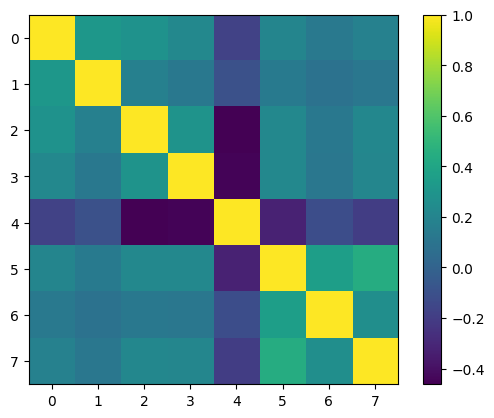

In [274]:
corr_matrix = data.corr(numeric_only=True)

plt.imshow(corr_matrix)
plt.colorbar()

## Task 5: Impute Missing values with Linear Regression

In [275]:
print("Amount of missing values per column/feature")
data.isnull().sum()

Amount of missing values per column/feature


,0
AGE,0
GENDER,0
RACE,0
DRIVING_EXPERIENCE,0
EDUCATION,0
INCOME,0
CREDIT_SCORE,982
VEHICLE_OWNERSHIP,0
VEHICLE_YEAR,0
MARRIED,0


In [276]:
def visualize_na(data, imputed_data):
  fig, axes = plt.subplots(1, 2, figsize=(16,6))
  axes[0].imshow(
      data.isna(),
      aspect="auto",
      interpolation="none"
  )
  axes[0].set_title("Before Imputation")
  axes[0].set_xlabel("Features")
  axes[0].set_ylabel("Rows")
  axes[0].set_xticks(range(len(data.columns)))
  axes[0].set_xticklabels(data.columns, rotation=90)

  axes[1].imshow(
      imputed_data.isna(),
      aspect="auto",
      interpolation="none"
  )

  axes[1].set_title("After Imputation")
  axes[1].set_xlabel("Features")
  axes[1].set_ylabel("Rows")
  axes[1].set_xticks(range(len(imputed_data.columns)))
  axes[1].set_xticklabels(imputed_data.columns, rotation=90)

  plt.tight_layout()
  plt.show()

In [277]:
def impute_regression(data, target_col, k=3):
  data = data.copy()

  numeric_df = data.select_dtypes(include=np.number)

  correlations = (
      numeric_df.corr()[target_col]
      .drop(target_col)
      .abs()
      .sort_values(ascending=False)
  )

  features = correlations.head(k).index.tolist()
  train_data = data[target_col].notna()
  missing_data = data[target_col].isna()

  X_train = data.loc[train_data, features].copy()
  y_train = data.loc[train_data, target_col]

  X_missing = data.loc[missing_data, features].copy()

  medians = X_train.median()
  X_train = X_train.fillna(medians)
  X_missing = X_missing.fillna(medians)

  model = LinearRegression()
  model.fit(X_train, y_train)

  data.loc[missing_data, target_col] = model.predict(X_missing)

  return data

In [278]:
imputed_data = impute_regression(data=data, target_col="CREDIT_SCORE", k=3)
imputed_data = impute_regression(data=imputed_data, target_col="ANNUAL_MILEAGE", k=3)

In [279]:
imputed_data.isnull().sum()

,0
AGE,0
GENDER,0
RACE,0
DRIVING_EXPERIENCE,0
EDUCATION,0
INCOME,0
CREDIT_SCORE,0
VEHICLE_OWNERSHIP,0
VEHICLE_YEAR,0
MARRIED,0


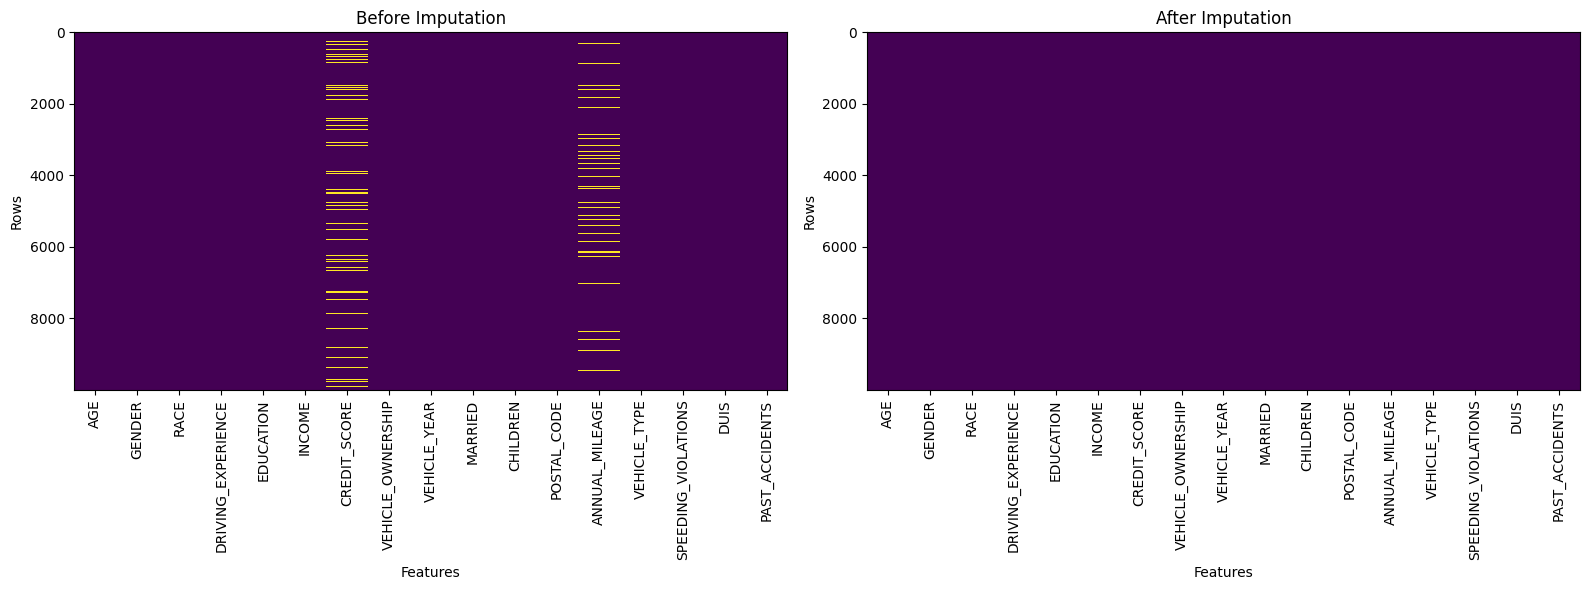

In [280]:
visualize_na(data, imputed_data)
data = imputed_data

## Task 6: Normalize Data

In [281]:
data_scaled = data.copy()

numerical_cols = data.select_dtypes(include=["int64", "float64"]).columns

scaler = MinMaxScaler()

data_scaled[numerical_cols] = scaler.fit_transform(data[numerical_cols])

In [282]:
speeding, past_accidents, duis = data["SPEEDING_VIOLATIONS"], data["PAST_ACCIDENTS"], data["DUIS"]
speeding_scaled, past_accidents_scaled, duis_scaled = data_scaled["SPEEDING_VIOLATIONS"], data_scaled["PAST_ACCIDENTS"], data_scaled["DUIS"]

## Task 7: Feature Engineering

Insurance Risk: $\frac{(Speeding Violation + DUIs + Past Accidents)}{(\max(Speeding Violation) + \max(DUIs) + \max(Past Accidents))}$

In [283]:
sv_max = data["SPEEDING_VIOLATIONS"].max()
dui_max = data["DUIS"].max()
pa_max = data["PAST_ACCIDENTS"].max()

max_vals = sv_max + dui_max + pa_max

data_scaled["INSURANCE_RISK"] = (data["SPEEDING_VIOLATIONS"] + data["DUIS"] + data["PAST_ACCIDENTS"]) / max_vals

data_scaled["INSURANCE_RISK"] = (
    data_scaled["INSURANCE_RISK"] - data_scaled["INSURANCE_RISK"].min()) / (
        data_scaled["INSURANCE_RISK"].max() - data_scaled["INSURANCE_RISK"].min()
    )

# data = data.drop(columns=["SPEEDING_VIOLATIONS", "DUIS", "PAST_ACCIDENTS"])

Car Estimated Age: Annual Mileage and Vehicle Year

In [284]:
median_mileage = data["ANNUAL_MILEAGE"].median()
estimated_age_conditions = [
    (data["ANNUAL_MILEAGE"] <= median_mileage) & (data["VEHICLE_YEAR"] == "before 2015"),
    (data["ANNUAL_MILEAGE"] <= median_mileage) & (data["VEHICLE_YEAR"] == "after 2015"),
    (data["ANNUAL_MILEAGE"] > median_mileage) & (data["VEHICLE_YEAR"] == "before 2015"),
    (data["ANNUAL_MILEAGE"] > median_mileage) & (data["VEHICLE_YEAR"] == "after 2015"),
]

estimated_age_values = [
    "Old",
    "Newer",
    "Very Old",
    "Old"
]

data_scaled["CAR_AGE"] = np.select(
    estimated_age_conditions,
    estimated_age_values,
    default="unknown"
)

# data = data.drop(column=["ANNUAL_MILEAGE", "VEHICLE_YEAR"])

Family Status: Married and Children

In [285]:
family_condition = [
    (data["MARRIED"] == 0) & (data["CHILDREN"] == 0),
    (data["MARRIED"] == 1) & (data["CHILDREN"] == 1),
    (data["MARRIED"] == 0) & (data["CHILDREN"] == 1),
    (data["MARRIED"] == 1) & (data["CHILDREN"] == 0)
]

family_values = [
    0,
    1,
    1,
    1
]

data_scaled["FAMILY"] = np.select(
    family_condition,
    family_values,
    default=0
)

# data = data.drop(columns=["MARRIED", "CHILDREN"])

In [286]:
data = data_scaled

## Task 8: One-Hot Encoding

One-Hot Encoded Data for Feature Selection, some EDA tasks requires non-encoded data

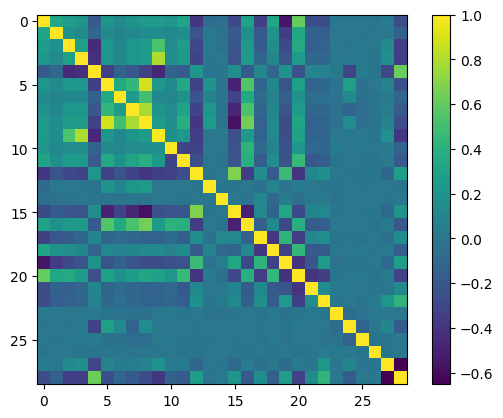

In [287]:
encoded_data = pd.get_dummies(data, dtype=int, drop_first=True)
corr_matrix = encoded_data.corr(numeric_only=True)
plt.imshow(corr_matrix)
plt.colorbar()

## Task 9: Step-wise Linear Regression Feature Selection

In [288]:
X = encoded_data
y = outcome

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=321,
    stratify=y
)

lr = LogisticRegression(max_iter=1000)

In [289]:
# Forward Sequential Feature Selection
sfs = SFS(
    lr,
    k_features="best",
    forward=True,
    floating=False,
    scoring="roc_auc",
    cv=5,
    n_jobs=-1
)

sfs.fit(X_train, y_train)

print("Selected features:")
print(sfs.k_feature_names_)

print("Best CV ROC-AUC:")
print(sfs.k_score_)

Selected features:
('VEHICLE_OWNERSHIP', 'MARRIED', 'ANNUAL_MILEAGE', 'INSURANCE_RISK', 'AGE_Middle Age', 'GENDER_male', 'RACE_minority', 'DRIVING_EXPERIENCE_Beginner', 'DRIVING_EXPERIENCE_Expert', 'INCOME_upper class', 'VEHICLE_YEAR_before 2015', 'POSTAL_CODE_21217', 'POSTAL_CODE_32765', 'POSTAL_CODE_92101')
Best CV ROC-AUC:
0.924168559711972


In [290]:
# Backward Sequential Feature Selection
sbs = SFS(
    lr,
    k_features="best",
    forward=False,
    floating=False,
    scoring="roc_auc",
    cv=5,
    n_jobs=-1
)

sbs.fit(X_train, y_train)

print("Selected features:")
print(sbs.k_feature_names_)

print("\nBest CV ROC-AUC:")
print(sbs.k_score_)

Selected features:
('VEHICLE_OWNERSHIP', 'MARRIED', 'ANNUAL_MILEAGE', 'INSURANCE_RISK', 'AGE_Middle Age', 'GENDER_male', 'RACE_minority', 'DRIVING_EXPERIENCE_Beginner', 'DRIVING_EXPERIENCE_Expert', 'INCOME_upper class', 'VEHICLE_YEAR_before 2015', 'POSTAL_CODE_21217', 'POSTAL_CODE_32765', 'POSTAL_CODE_92101')

Best CV ROC-AUC:
0.924168559711972


In [291]:
# Forward selection with backward elimination
stepwise_sfs = SFS(
    lr,
    k_features="best",
    forward=True,
    floating=True,
    scoring="roc_auc",
    cv=5,
    n_jobs=-1
)

stepwise_sfs.fit(X_train, y_train)

print("Selected features:")
print(stepwise_sfs.k_feature_names_)

print("\nNumber of selected features:")
print(len(stepwise_sfs.k_feature_names_))

print("\nBest CV ROC-AUC:")
print(stepwise_sfs.k_score_)

Selected features:
('VEHICLE_OWNERSHIP', 'MARRIED', 'ANNUAL_MILEAGE', 'INSURANCE_RISK', 'AGE_Middle Age', 'GENDER_male', 'RACE_minority', 'DRIVING_EXPERIENCE_Beginner', 'DRIVING_EXPERIENCE_Expert', 'INCOME_upper class', 'VEHICLE_YEAR_before 2015', 'POSTAL_CODE_21217', 'POSTAL_CODE_32765', 'POSTAL_CODE_92101')

Number of selected features:
14

Best CV ROC-AUC:
0.924168559711972


In [292]:
def stepwise_summary(selectors):
    rows = []

    for label, selector in selectors.items():
        features = list(selector.k_feature_names_)
        rows.append({
            "direction": label,
            "n_features": len(features),
            "cv_roc_auc": round(selector.k_score_, 4),
            "features": ", ".join(sorted(features)),
        })

    return (pd.DataFrame(rows)
            .sort_values("cv_roc_auc", ascending=False)
            .reset_index(drop=True))

selectors = {
    "forward": sfs,
    "backward": sbs,
    "both (floating)": stepwise_sfs,
}

display(stepwise_summary(selectors))

,direction,n_features,cv_roc_auc,features
0,forward,14,0.9242,"AGE_Middle Age, ANNUAL_MILEAGE, DRIVING_EXPERI..."
1,backward,14,0.9242,"AGE_Middle Age, ANNUAL_MILEAGE, DRIVING_EXPERI..."
2,both (floating),14,0.9242,"AGE_Middle Age, ANNUAL_MILEAGE, DRIVING_EXPERI..."


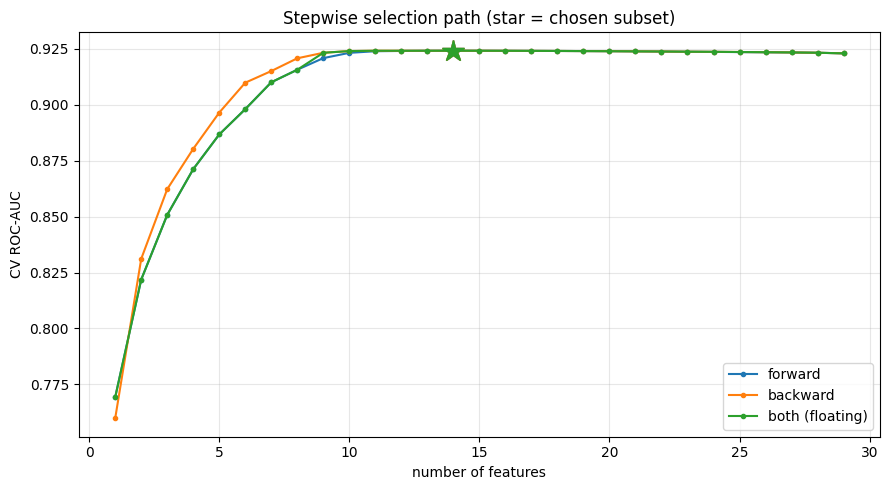

In [293]:
def plot_stepwise_paths(selectors):
    fig, ax = plt.subplots(figsize=(9, 5))

    for label, selector in selectors.items():

        metrics = selector.get_metric_dict()
        sizes = sorted(metrics)
        scores = [metrics[k]["avg_score"] for k in sizes]

        line, = ax.plot(sizes, scores, marker="o", markersize=3, label=label)

        best_size = len(selector.k_feature_names_)
        ax.plot(best_size, selector.k_score_, marker="*", markersize=16,
                color=line.get_color(), linestyle="none")

    ax.set_xlabel("number of features")
    ax.set_ylabel("CV ROC-AUC")
    ax.set_title("Stepwise selection path (star = chosen subset)")
    ax.legend()
    ax.grid(alpha=0.3)

    plt.tight_layout()
    plt.show()

    return None


plot_stepwise_paths(selectors)

## Task 10: Random Forest-based Feature Selection

In [294]:
X = encoded_data
y = outcome

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=123,
    stratify=y
)

rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=123,
    n_jobs=1
)

rf_model.fit(X_train, y_train)

feature_counts = np.zeros(X_train.shape[1], dtype=int)

for tree in rf_model.estimators_:
  features_used = tree.tree_.feature
  features_used = features_used[features_used >= 0]
  unique_features = np.unique(features_used)
  feature_counts[unique_features] += 1

feature_recurrence = feature_counts / len(rf_model.estimators_)
feature_selection = pd.DataFrame({
    "feature": X_train.columns,
    "tree_count": feature_counts,
    "recurrence": feature_recurrence,
    "importance": rf_model.feature_importances_
})

feature_selection = feature_selection.sort_values(
    by="importance",
    ascending=False
)

print(feature_selection)

                        feature  tree_count  recurrence  importance
0                  CREDIT_SCORE         100         1.0    0.153941
4                ANNUAL_MILEAGE         100         1.0    0.092841
15  DRIVING_EXPERIENCE_Beginner         100         1.0    0.083187
8                INSURANCE_RISK         100         1.0    0.081579
1             VEHICLE_OWNERSHIP         100         1.0    0.078686
5           SPEEDING_VIOLATIONS         100         1.0    0.044241
22     VEHICLE_YEAR_before 2015         100         1.0    0.041722
16    DRIVING_EXPERIENCE_Expert         100         1.0    0.036134
7                PAST_ACCIDENTS         100         1.0    0.034990
12              AGE_Young-Adult         100         1.0    0.033239
13                  GENDER_male         100         1.0    0.033205
23            POSTAL_CODE_21217         100         1.0    0.027965
24            POSTAL_CODE_32765         100         1.0    0.024401
20           INCOME_upper class         100     

In [295]:
def visualize_rf(feature_selection):
  plt.figure(figsize=(10, 8))

  plt.barh(
      feature_selection["feature"],
      feature_selection["importance"]
  )

  plt.xlabel("Feature Importance")
  plt.ylabel("Feature")
  plt.title("Random Forest Feature Importance")
  plt.gca().invert_yaxis()
  plt.tight_layout()
  plt.show()

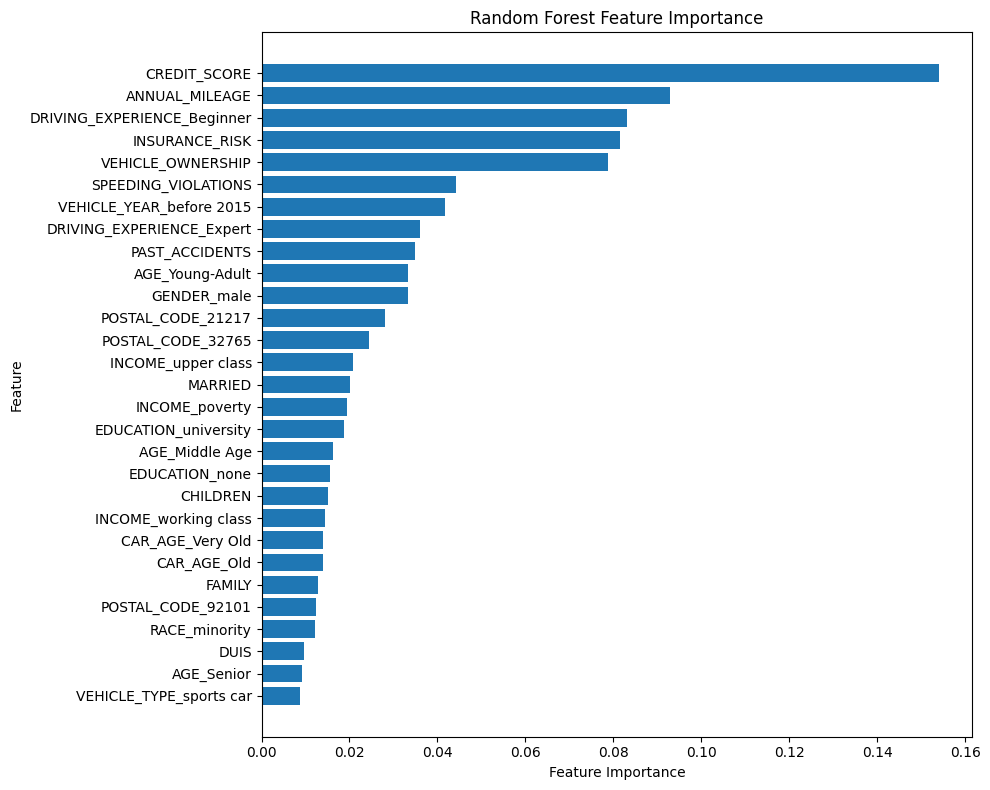

In [296]:
visualize_rf(feature_selection)

In [297]:
threshold = 0.02
features_selected = feature_selection.loc[
    feature_selection["importance"] > threshold, "feature"
].tolist()

rf_enc_data = encoded_data[features_selected]

## Task 11: PCA

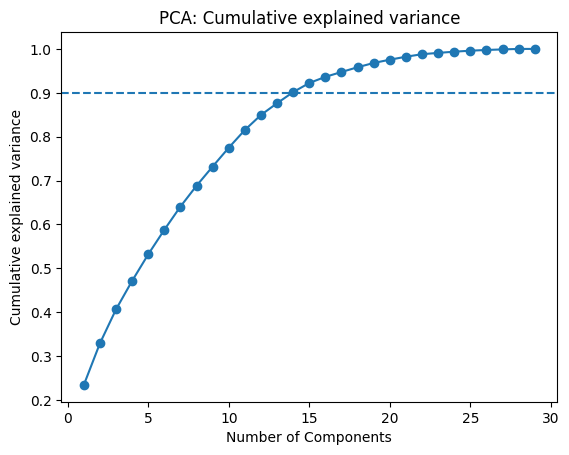

14 components explain 90% of variace (origina: 20 features)


In [298]:
features = encoded_data.copy().astype(float)

pca = PCA().fit(features)
cumulative_sum = np.cumsum(pca.explained_variance_ratio_)
number_comp = np.argmax(cumulative_sum >= 0.90) + 1

plt.plot(range(1, len(cumulative_sum) + 1), cumulative_sum, marker="o")
plt.axhline(0.90, ls="--")

plt.xlabel("Number of Components")
plt.ylabel("Cumulative explained variance")
plt.title("PCA: Cumulative explained variance")
plt.show()
print(f"{number_comp} components explain 90% of variace (origina: {data.shape[1]} features)")

# Section 2: Exploratory Data Analysis

- data = non-encoded data
- encoded_data = one-hot encoded data
- rf_enc_data = one-hot encoded data with random forest based feature selection

In [299]:
print(rf_enc_data)

      CREDIT_SCORE  ANNUAL_MILEAGE  DRIVING_EXPERIENCE_Beginner  \
0         0.634374         0.50000                            1   
1         0.335441         0.70000                            1   
2         0.484636         0.45000                            1   
3         0.168222         0.45000                            1   
4         0.369171         0.50000                            0   
...            ...             ...                          ...   
9995      0.583418         0.70000                            0   
9996      0.516688         0.49731                            0   
9997      0.460166         0.60000                            1   
9998      0.342524         0.55000                            0   
9999      0.420808         0.55000                            1   

      INSURANCE_RISK  VEHICLE_OWNERSHIP  SPEEDING_VIOLATIONS  \
0           0.000000                1.0             0.000000   
1           0.000000                0.0             0.000000   
2  

## Task 1-3: Mean/Mode/Median

In [300]:
brian_data = pd.concat([data.copy(), outcome], axis=1)
brian_encoded = encoded_data.copy()

# --- Group the preprocessed columns automatically ----------------------
def classify_columns(df, count_max=30, id_like=("POSTAL_CODE")):
    groups = {"continuous": [], "count": [], "binary": [], "categorical": []}

    for col in df.columns:
        if col in id_like:
            groups["categorical"].append(col)
            continue

        values = df[col]

        if df[col].dtype == bool:
            groups["binary"].append(col)
        elif not pd.api.types.is_numeric_dtype(df[col]):
            groups["categorical"].append(col)
        elif set(df[col].unique()) <= {0, 1}:
            groups["binary"].append(col)
        elif (values.dtype.kind in "iu" and values.min() >= 0
              and values.max() <= count_max):
            groups["count"].append(col)
        else:
            groups["continuous"].append(col)

    return groups

# --- Group the columns by what a mean/median/mode actually means -------
def central_tendency(df, columns):
    summary = pd.DataFrame({
        "mean": df[columns].mean(),
        "median": df[columns].median(),
        # mode() can return several values; take the first (lowest) one
        "mode": [df[col].mode().iloc[0] for col in columns],
        "std": df[columns].std(),
        "skew": df[columns].skew(),
        "min": df[columns].min(),
        "max": df[columns].max(),
        "n_unique": df[columns].nunique(),
    })
    return summary.round(4)


# --- Mode for the categorical columns ----------------------------------
def categorical_modes(df, columns, sort=True):
    rows = []

    for col in columns:

        counts = df[col].value_counts()

        rows.append({
            "column": col,
            "mode": counts.index[0],
            "count": counts.iloc[0],
            "share_%": round(counts.iloc[0] / len(df) * 100, 1),
            "n_categories": df[col].nunique(),
            # The runner-up shows whether the mode really stands out
            "second": counts.index[1] if len(counts) > 1 else None,
            "second_share_%": (round(counts.iloc[1] / len(df) * 100, 1)
                               if len(counts) > 1 else None),
        })
    result = pd.DataFrame(rows)

    if sort:
        result = result.sort_values("share_%", ascending=False)

    return result.reset_index(drop=True)



groups = classify_columns(brian_data)
for name, cols in groups.items():
    print(f"{name:12s} ({len(cols):2d}): {cols}")

continuous   ( 6): ['CREDIT_SCORE', 'ANNUAL_MILEAGE', 'SPEEDING_VIOLATIONS', 'DUIS', 'PAST_ACCIDENTS', 'INSURANCE_RISK']
count        ( 0): []
binary       ( 5): ['VEHICLE_OWNERSHIP', 'MARRIED', 'CHILDREN', 'FAMILY', 'OUTCOME']
categorical  (10): ['AGE', 'GENDER', 'RACE', 'DRIVING_EXPERIENCE', 'EDUCATION', 'INCOME', 'VEHICLE_YEAR', 'POSTAL_CODE', 'VEHICLE_TYPE', 'CAR_AGE']


In [301]:
# --- The three statistics on the preprocessed frame --------------------
print("CONTINUOUS")
display(central_tendency(brian_data, groups["continuous"]))

print("COUNTS")
display(central_tendency(brian_data, groups["count"]))

print("BINARY FLAGS")
display(central_tendency(brian_data, groups["binary"]))

print("CATEGORICAL")
display(categorical_modes(brian_data, groups["categorical"]))

CONTINUOUS


,mean,median,mode,std,skew,min,max,n_unique
CREDIT_SCORE,0.5094,0.5174,0.5164,0.1451,-0.2298,0.0,1.0,9133
ANNUAL_MILEAGE,0.4851,0.5000,0.4500,0.1348,0.0294,0.0,1.0,920
SPEEDING_VIOLATIONS,0.0674,0.0000,0.0000,0.1019,2.3655,0.0,1.0,21
DUIS,0.0399,0.0000,0.0000,0.0925,2.7579,0.0,1.0,7
PAST_ACCIDENTS,0.0704,0.0000,0.0000,0.1102,2.1489,0.0,1.0,15
INSURANCE_RISK,0.0992,0.0714,0.0000,0.1274,1.7138,0.0,1.0,27


COUNTS


,mean,median,mode,std,skew,min,max,n_unique


BINARY FLAGS


,mean,median,mode,std,skew,min,max,n_unique
VEHICLE_OWNERSHIP,0.6970,1.0,1.0,0.4596,-0.8575,0.0,1.0,2
MARRIED,0.4982,0.0,False,0.5000,0.0072,False,True,2
CHILDREN,0.6888,1.0,True,0.4630,-0.8157,False,True,2
FAMILY,0.7774,1.0,1,0.4160,-1.3339,0,1,2
OUTCOME,0.3133,0.0,0.0,0.4639,0.8051,0.0,1.0,2


CATEGORICAL


,column,mode,count,share_%,n_categories,second,second_share_%
0,VEHICLE_TYPE,sedan,9523,95.2,2,sports car,4.8
1,RACE,majority,9012,90.1,2,minority,9.9
2,VEHICLE_YEAR,before 2015,6967,69.7,2,after 2015,30.3
3,POSTAL_CODE,10238,6940,69.4,4,32765,24.6
4,CAR_AGE,Old,5061,50.6,3,Very Old,29.3
5,GENDER,female,5010,50.1,2,male,49.9
6,INCOME,upper class,4336,43.4,4,middle class,21.4
7,EDUCATION,high school,4157,41.6,3,university,39.3
8,DRIVING_EXPERIENCE,Beginner,3530,35.3,3,Advanced,33.0
9,AGE,Adult,3063,30.6,4,Middle Age,29.3


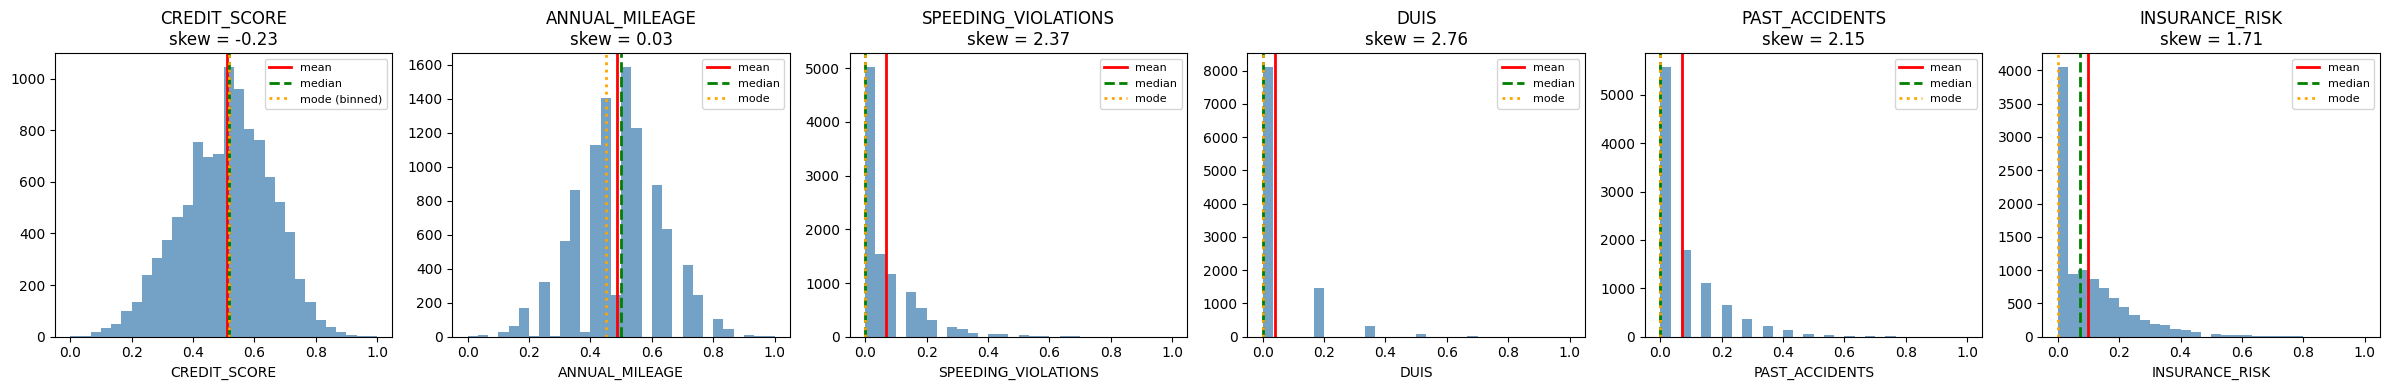

In [302]:
# --- Plot the three statistics on each distribution --------------------
def plot_central_tendency(df, columns, bins=30, unique_ratio=0.5):
    fig, axes = plt.subplots(1, len(columns), figsize=(4 * len(columns), 4))
    axes = np.atleast_1d(axes)

    for ax, col in zip(axes, columns):
        values = df[col].dropna()
        sns.histplot(values, bins=bins, ax=ax, color="steelblue", edgecolor="none")

        # Mode: the binned peak for continuous columns, the raw value otherwise
        if values.nunique() / len(values) > unique_ratio:
            peak = pd.cut(values, bins=bins).value_counts().idxmax()
            mode_value = peak.mid
            mode_label = "mode (binned)"
        else:
            mode_value = values.mode().iloc[0]
            mode_label = "mode"

        ax.axvline(values.mean(), color="red", linestyle="-", lw=2, label="mean")
        ax.axvline(values.median(), color="green", linestyle="--", lw=2, label="median")
        ax.axvline(mode_value, color="orange", linestyle=":", lw=2, label=mode_label)

        ax.set_title(f"{col}\nskew = {values.skew():.2f}")
        ax.set_ylabel("")
        ax.legend(fontsize=8)

    plt.tight_layout()
    plt.show()

    return None

plot_central_tendency(data, groups["continuous"] + groups["count"])

In [303]:
# --- Mode for the categorical columns ----------------------------------
def categorical_modes(df, columns, sort=True):
    rows = []
    for col in columns:
        counts = df[col].value_counts()
        rows.append({
            "column": col,
            "mode": counts.index[0],
            "count": counts.iloc[0],
            "share_%": round(counts.iloc[0] / len(df) * 100, 1),
            "n_categories": df[col].nunique(),
            # The runner-up shows whether the mode really stands out
            "second": counts.index[1] if len(counts) > 1 else None,
            "second_share_%": (round(counts.iloc[1] / len(df) * 100, 1)
                               if len(counts) > 1 else None),
        })
    result = pd.DataFrame(rows)
    if sort:
        result = result.sort_values("share_%", ascending=False)
    return result.reset_index(drop=True)


display(categorical_modes(data, groups["categorical"]))

,column,mode,count,share_%,n_categories,second,second_share_%
0,VEHICLE_TYPE,sedan,9523,95.2,2,sports car,4.8
1,RACE,majority,9012,90.1,2,minority,9.9
2,VEHICLE_YEAR,before 2015,6967,69.7,2,after 2015,30.3
3,POSTAL_CODE,10238,6940,69.4,4,32765,24.6
4,CAR_AGE,Old,5061,50.6,3,Very Old,29.3
5,GENDER,female,5010,50.1,2,male,49.9
6,INCOME,upper class,4336,43.4,4,middle class,21.4
7,EDUCATION,high school,4157,41.6,3,university,39.3
8,DRIVING_EXPERIENCE,Beginner,3530,35.3,3,Advanced,33.0
9,AGE,Adult,3063,30.6,4,Middle Age,29.3


## Task 4: Linear Regression on Outcome, Past Accidents, DUIs, and Speeding Violations

### Diagnostic plot code
Reference: https://robert-alvarez.github.io/2018-06-04-diagnostic_plots/

In [304]:
def diagnostic_plots(model, x, y):
  dataframe = pd.concat([x, y], axis=1)
  fitted = model.fittedvalues
  residuals = model.resid
  norm_residuals = model.get_influence().resid_studentized_internal
  norm_residuals_abs_sqrt = np.sqrt(np.abs(norm_residuals))
  abs_resid = np.abs(residuals)
  leverage = model.get_influence().hat_matrix_diag
  cooks = model.get_influence().cooks_distance[0]

  fig, axes = plt.subplots(2, 2, figsize=(12, 10))
  ax = axes[0, 0]
  sns.residplot(x=fitted,
    y=dataframe.columns[-1],
    data=dataframe,
    lowess=True,
    scatter_kws={'alpha':0.5},
    line_kws={'color': 'red', 'lw':1, 'alpha': 0.8},
    ax=ax)
  ax.set_title("Residuals vs Fitted")
  ax.set_xlabel("Fitted values")
  ax.set_ylabel("Residuals")

  ax = axes[0, 1]
  QQ = ProbPlot(norm_residuals)

  QQ.qqplot(line="45", alpha=0.5, color="#4C72B0", lw=1, ax=ax)
  ax.set_title("Normal Q-Q")
  ax.set_xlabel("Theoretical Quantiles")
  ax.set_ylabel("Standardized Residuals")

  abs_norm_resid = np.flip(np.argsort(np.abs(norm_residuals)), 0)
  abs_norm_resid_top_3 = abs_norm_resid[:3]
  for r, i in enumerate(abs_norm_resid_top_3):
    ax.annotate(i,
                xy=(np.flip(QQ.theoretical_quantiles, 0)[r],
                    norm_residuals[i]))

  ax = axes[1, 0]
  sns.scatterplot(x=fitted, y=norm_residuals_abs_sqrt, alpha=0.5, ax=ax)
  sns.regplot(
      x=fitted,
      y=norm_residuals_abs_sqrt,
      scatter=False,
      ci=False,
      lowess=True,
      line_kws={'color': 'red', 'lw': 1, 'alpha': 0.8},
      ax=ax
  )
  ax.set_title("Scale-Location")
  ax.set_xlabel("Fitted values")
  ax.set_ylabel('sqrt{|Standardized Residuals|}')
  abs_sq_norm_resid = np.flip(np.argsort(norm_residuals_abs_sqrt), 0)
  abs_sq_norm_resid_top_3 = abs_sq_norm_resid[:3]
  for i in abs_sq_norm_resid_top_3:
    ax.annotate(
        i,
        xy=(fitted[i],
            norm_residuals_abs_sqrt[i])
    )

  ax = axes[1, 1]
  sns.scatterplot(
      x=leverage,
      y=norm_residuals,
      alpha=0.5,
      ax=ax
  )
  sns.regplot(
      x=leverage,
      y=norm_residuals,
      scatter=False,
      ci=False,
      lowess=True,
      line_kws={'color': 'red', 'lw': 1, 'alpha': 0.8},
      ax=ax
  )
  ax.set_xlim(0, max(leverage)+0.01)
  ax.set_ylim(-3, 5)
  ax.set_title('Residuals vs Leverage')
  ax.set_xlabel('Leverage')
  ax.set_ylabel('Standardized Residuals')

  leverage_top_3 = np.flip(np.argsort(cooks), 0)[:3]
  for i in leverage_top_3:
    ax.annotate(
        i,
        xy=(leverage[i],
            norm_residuals[i])
    )


### Linear Regression on Outcome

In [305]:
claim_features = sm.add_constant(rf_enc_data.astype(float))
claim_lr_model = sm.OLS(outcome, claim_features).fit()

print(claim_lr_model.summary())

                            OLS Regression Results                            
Dep. Variable:                OUTCOME   R-squared:                       0.460
Model:                            OLS   Adj. R-squared:                  0.459
Method:                 Least Squares   F-statistic:                     566.4
Date:                Sun, 27 Sep 2026   Prob (F-statistic):               0.00
Time:                        01:55:02   Log-Likelihood:                -3428.7
No. Observations:               10000   AIC:                             6889.
Df Residuals:                    9984   BIC:                             7005.
Df Model:                          15                                         
Covariance Type:            nonrobust                                         
                                  coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------------------
const             

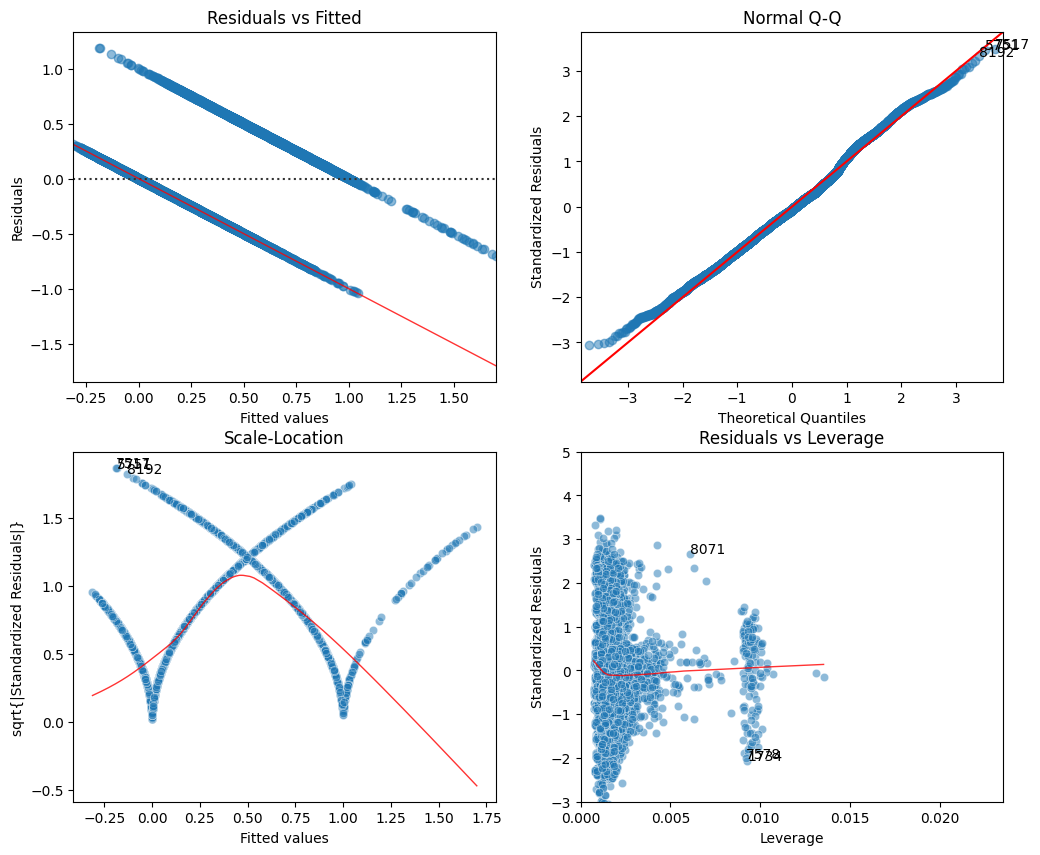

In [306]:
diagnostic_plots(
    claim_lr_model,
    x=encoded_data,
    y=outcome
)

### Linear Regression on Past Accidents, DUIs, and Speeding Violations

In [307]:
encoded_data = encoded_data.drop(columns=["SPEEDING_VIOLATIONS"])
features_speeding = sm.add_constant(encoded_data.astype(float))

encoded_data["SPEEDING_VIOLATIONS"] = speeding_scaled
encoded_data = encoded_data.drop(columns=["PAST_ACCIDENTS"])

features_pa = sm.add_constant(encoded_data.astype(float))

encoded_data["PAST_ACCIDENTS"] = past_accidents_scaled
encoded_data = encoded_data.drop(columns=["DUIS"])

features_duis = sm.add_constant(encoded_data.astype(float))

encoded_data["DUIS"] = duis_scaled

                             OLS Regression Results                            
Dep. Variable:     SPEEDING_VIOLATIONS   R-squared:                       1.000
Model:                             OLS   Adj. R-squared:                  1.000
Method:                  Least Squares   F-statistic:                 1.193e+31
Date:                 Sun, 27 Sep 2026   Prob (F-statistic):               0.00
Time:                         01:55:19   Log-Likelihood:             3.0614e+05
No. Observations:                10000   AIC:                        -6.122e+05
Df Residuals:                     9971   BIC:                        -6.120e+05
Df Model:                           28                                         
Covariance Type:             nonrobust                                         
                                  coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------------------
const   

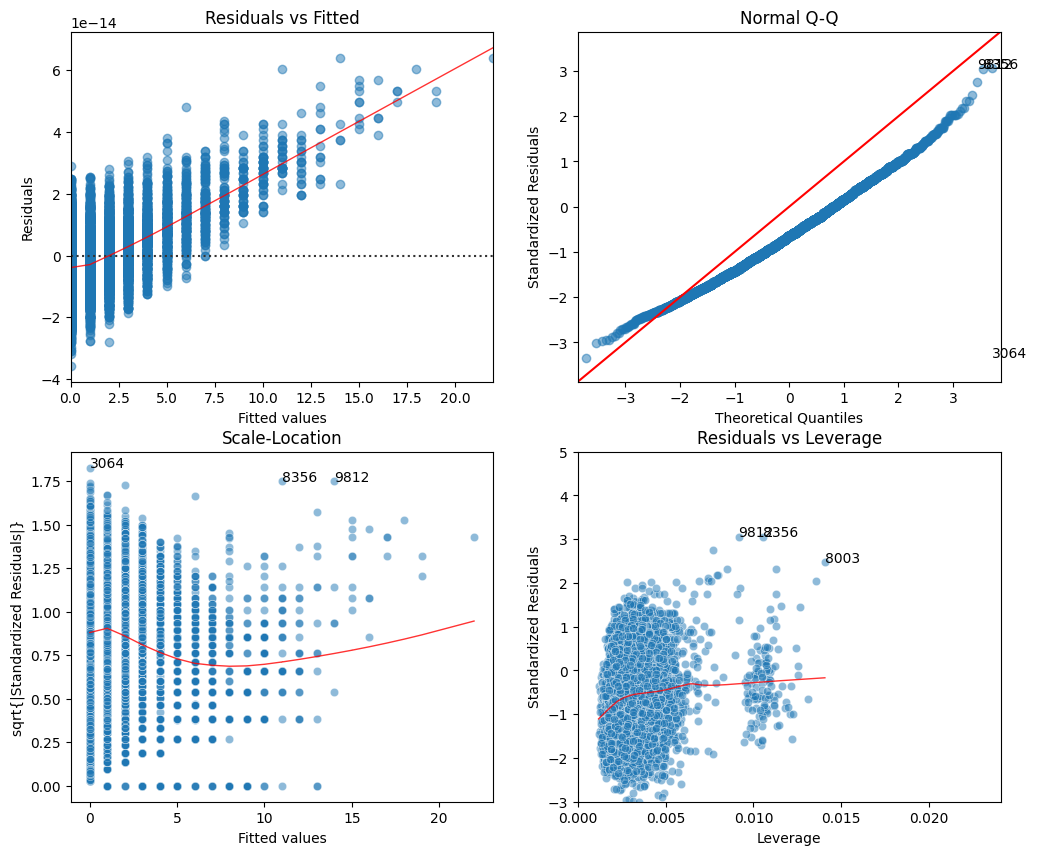

In [308]:
speeding_lr_model = sm.OLS(speeding, features_speeding).fit()
print(speeding_lr_model.summary())
diagnostic_plots(
    speeding_lr_model,
    x=features_speeding,
    y=speeding
)

                            OLS Regression Results                            
Dep. Variable:         PAST_ACCIDENTS   R-squared:                       1.000
Model:                            OLS   Adj. R-squared:                  1.000
Method:                 Least Squares   F-statistic:                 2.867e+31
Date:                Sun, 27 Sep 2026   Prob (F-statistic):               0.00
Time:                        01:55:31   Log-Likelihood:             3.1358e+05
No. Observations:               10000   AIC:                        -6.271e+05
Df Residuals:                    9971   BIC:                        -6.269e+05
Df Model:                          28                                         
Covariance Type:            nonrobust                                         
                                  coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------------------
const             

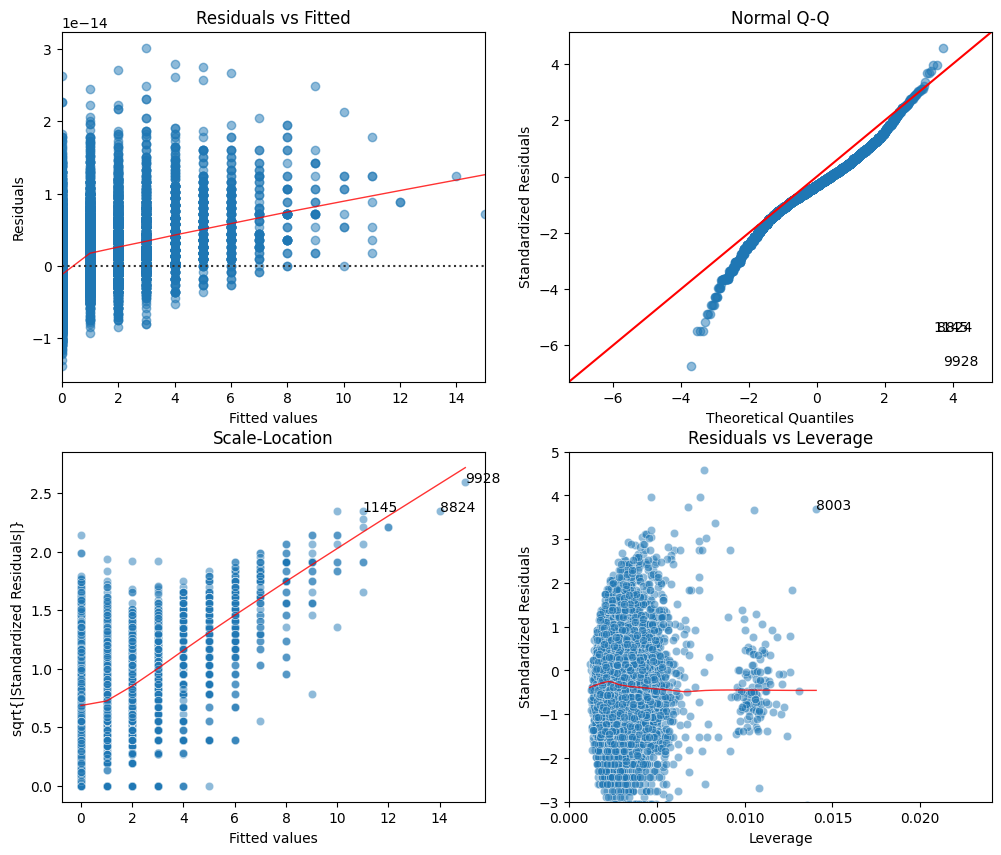

In [309]:
pa_lr_model = sm.OLS(past_accidents, features_pa).fit()
print(pa_lr_model.summary())
diagnostic_plots(
    pa_lr_model,
    x=features_pa,
    y=past_accidents
)

                            OLS Regression Results                            
Dep. Variable:                   DUIS   R-squared:                       1.000
Model:                            OLS   Adj. R-squared:                  1.000
Method:                 Least Squares   F-statistic:                 2.388e+29
Date:                Sun, 27 Sep 2026   Prob (F-statistic):               0.00
Time:                        01:55:42   Log-Likelihood:             3.0055e+05
No. Observations:               10000   AIC:                        -6.010e+05
Df Residuals:                    9971   BIC:                        -6.008e+05
Df Model:                          28                                         
Covariance Type:            nonrobust                                         
                                  coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------------------
const             

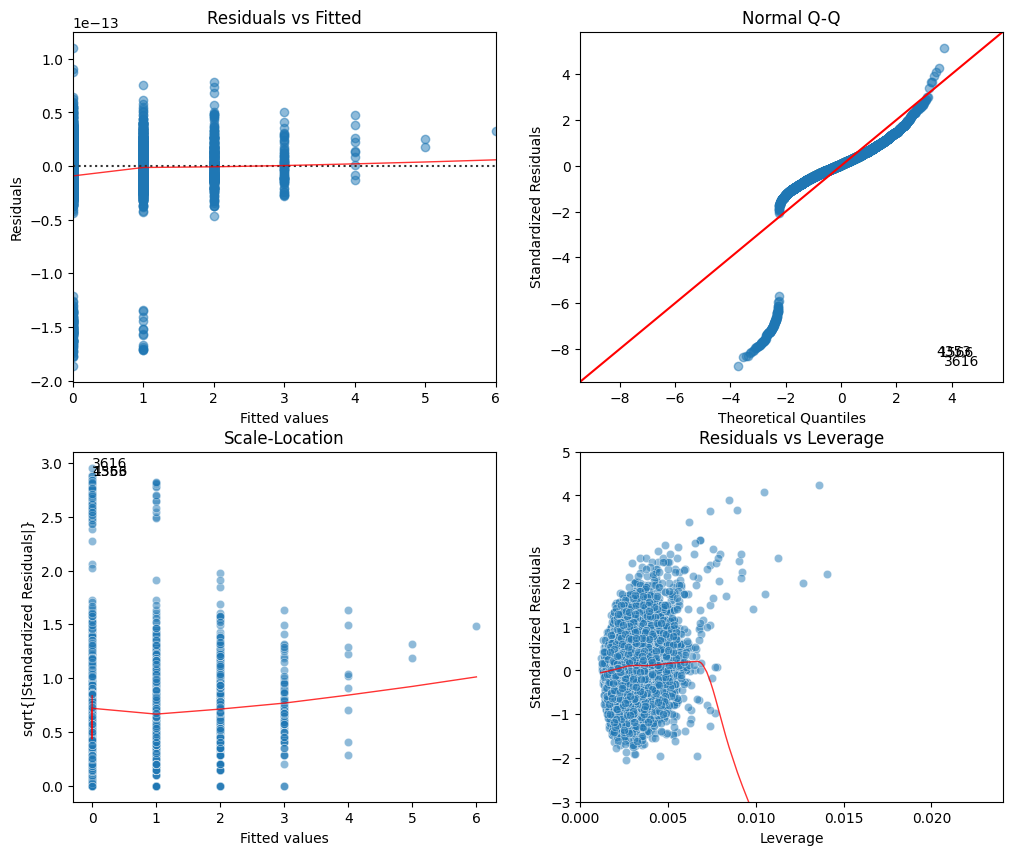

In [310]:
duis_lr_model = sm.OLS(duis, features_duis).fit()
print(duis_lr_model.summary())
diagnostic_plots(
    duis_lr_model,
    x=features_duis,
    y=duis
)

## Task 5: Negative Binomial Regression on count based features: Past Accidents, DUIs, and Speeding Violations

### Diagnostic plot code

In [311]:
def diagnostic_plots_glm(model):
  fitted = model.fittedvalues
  pearson_resid = model.resid_pearson
  deviance_resid = model.resid_deviance
  influence = model.get_influence()
  leverage = influence.hat_matrix_diag
  fig, axes = plt.subplots(2, 2, figsize=(12, 10))

  ax = axes[0, 0]
  ax.scatter(
      x=fitted,
      y=pearson_resid,
      alpha=0.7
  )
  sns.regplot(
      x=fitted,
      y=pearson_resid,
      scatter=False,
      lowess=True,
      ci=None,
      line_kws={'color': 'red', 'lw': 1, 'alpha': 0.8},
      ax=ax
  )
  ax.set_title("Pearson Residuals vs Fitted")
  ax.set_xlabel("Fitted values")
  ax.set_ylabel("Pearson residuals")

  ax = axes[0, 1]
  QQ = ProbPlot(deviance_resid)

  QQ.qqplot(
      line="45",
      alpha=0.5,
      ax=ax
  )
  ax.set_title("Q-Q Plot of Deviance Residuals")
  ax.set_xlabel("Theoretical Quantiles")
  ax.set_ylabel("Deviance Residuals")

  ax = axes[1, 0]
  scaled_resid = np.sqrt(np.abs(pearson_resid))

  sns.scatterplot(
      x=fitted,
      y=scaled_resid,
      alpha=0.5,
      ax=ax
  )

  sns.regplot(
      x=fitted,
      y=scaled_resid,
      scatter=False,
      lowess=True,
      ci=None,
      line_kws={'color': 'red', 'lw': 1, 'alpha':0.8},
      ax=ax
  )

  ax.set_title("Scale-Location")
  ax.set_xlabel("Fitted values")
  ax.set_ylabel("sqrt{|Pearson Residuals|}")

  ax = axes[1, 1]
  sns.scatterplot(
      x=leverage,
      y=pearson_resid,
      alpha=0.5,
      ax=ax
  )
  sns.regplot(
      x=leverage,
      y=pearson_resid,
      scatter=False,
      lowess=True,
      ci=None,
      line_kws={'color': 'red', 'lw': 1, 'alpha': 0.8},
      ax=ax
  )

  ax.set_title("Pearson Residuals vs Leverage")
  ax.set_xlabel("Leverage")
  ax.set_ylabel("Pearson residuals")

  plt.tight_layout()
  plt.show()

### Models

/tmp/ipykernel_5733/3101001203.py:4: ValueWarning: Negative binomial dispersion parameter alpha not set. Using default value alpha=1.0.
  family=sm.families.NegativeBinomial()


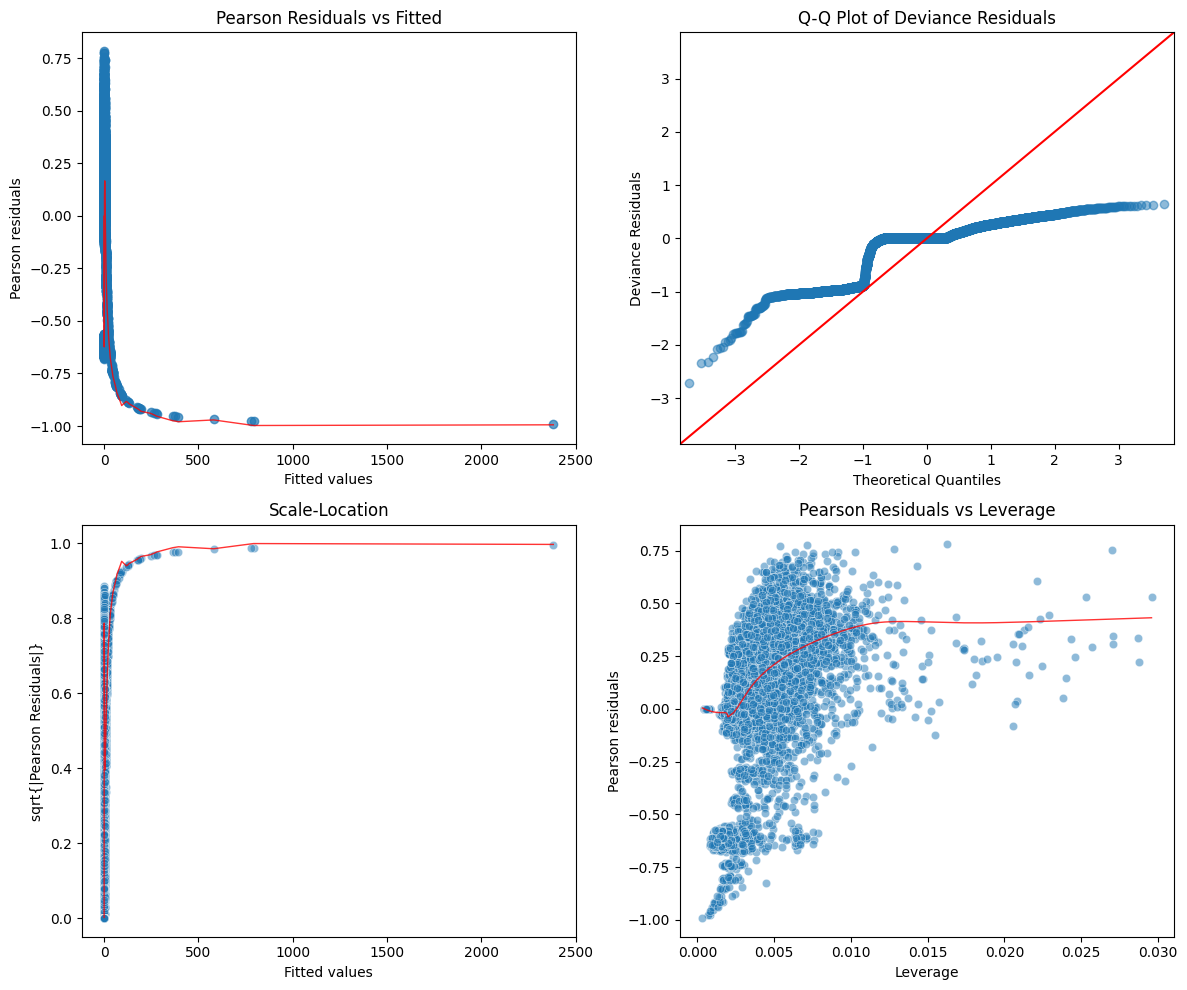

                  Generalized Linear Model Regression Results                  
Dep. Variable:     SPEEDING_VIOLATIONS   No. Observations:                10000
Model:                             GLM   Df Residuals:                     9971
Model Family:         NegativeBinomial   Df Model:                           28
Link Function:                     Log   Scale:                          1.0000
Method:                           IRLS   Log-Likelihood:                -11230.
Date:                 Sun, 27 Sep 2026   Deviance:                       1971.1
Time:                         01:56:11   Pearson chi2:                 1.04e+03
No. Iterations:                     28   Pseudo R-squ. (CS):             0.6676
Covariance Type:             nonrobust                                         
                                  coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------------------
const   

In [312]:
speeding_nb_model = sm.GLM(
    speeding,
    features_speeding,
    family=sm.families.NegativeBinomial()
).fit()
diagnostic_plots_glm(speeding_nb_model)
print(speeding_nb_model.summary())

/tmp/ipykernel_5733/2360089693.py:4: ValueWarning: Negative binomial dispersion parameter alpha not set. Using default value alpha=1.0.
  family=sm.families.NegativeBinomial()


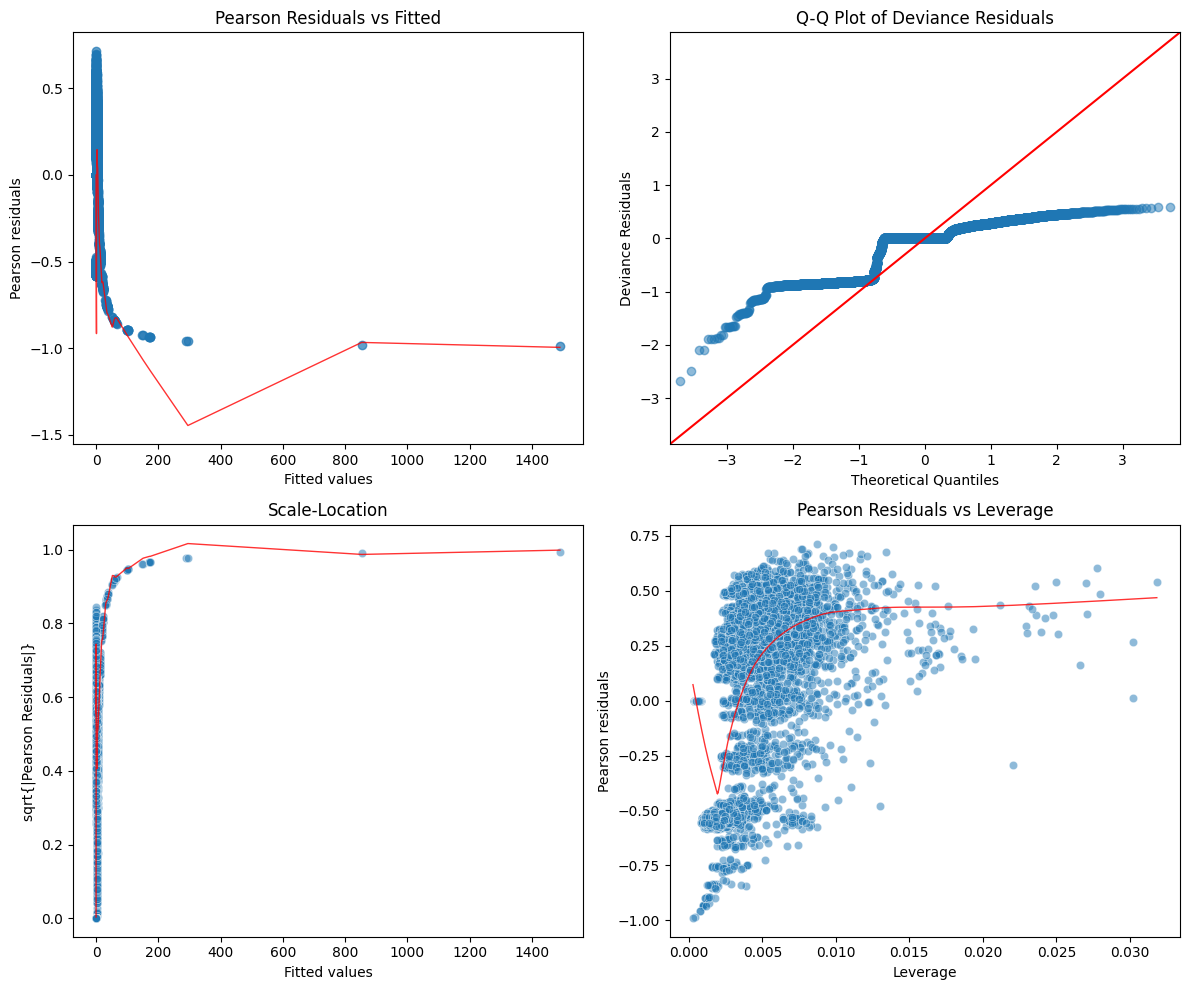

                 Generalized Linear Model Regression Results                  
Dep. Variable:         PAST_ACCIDENTS   No. Observations:                10000
Model:                            GLM   Df Residuals:                     9971
Model Family:        NegativeBinomial   Df Model:                           28
Link Function:                    Log   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -9424.8
Date:                Sun, 27 Sep 2026   Deviance:                       1985.0
Time:                        01:56:27   Pearson chi2:                 1.12e+03
No. Iterations:                    28   Pseudo R-squ. (CS):             0.6187
Covariance Type:            nonrobust                                         
                                  coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------------------
const             

In [313]:
pa_nb_model = sm.GLM(
    past_accidents,
    features_pa,
    family=sm.families.NegativeBinomial()
).fit()
diagnostic_plots_glm(pa_nb_model)
print(pa_nb_model.summary())

/tmp/ipykernel_5733/1951785216.py:4: ValueWarning: Negative binomial dispersion parameter alpha not set. Using default value alpha=1.0.
  family=sm.families.NegativeBinomial()


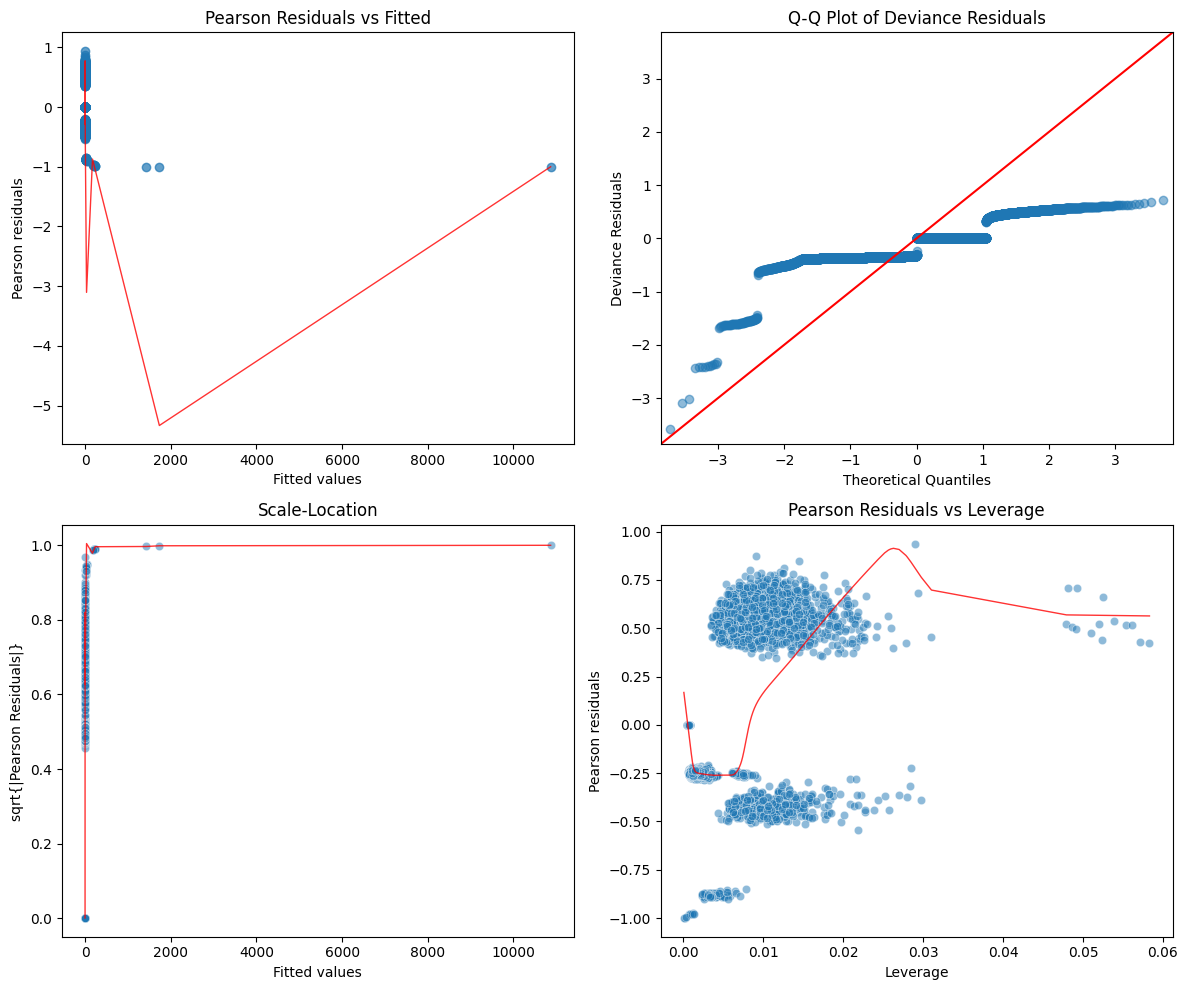

                 Generalized Linear Model Regression Results                  
Dep. Variable:                   DUIS   No. Observations:                10000
Model:                            GLM   Df Residuals:                     9971
Model Family:        NegativeBinomial   Df Model:                           28
Link Function:                    Log   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -3489.3
Date:                Sun, 27 Sep 2026   Deviance:                       1266.3
Time:                        01:56:43   Pearson chi2:                     888.
No. Iterations:                    26   Pseudo R-squ. (CS):             0.4043
Covariance Type:            nonrobust                                         
                                  coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------------------
const             

In [314]:
duis_nb_model = sm.GLM(
    duis,
    features_duis,
    family=sm.families.NegativeBinomial()
).fit()
diagnostic_plots_glm(duis_nb_model)
print(duis_nb_model.summary())

## Task 6: Poisson Regression on count based features: Past Accidents, DUIs, and Speeding Violations

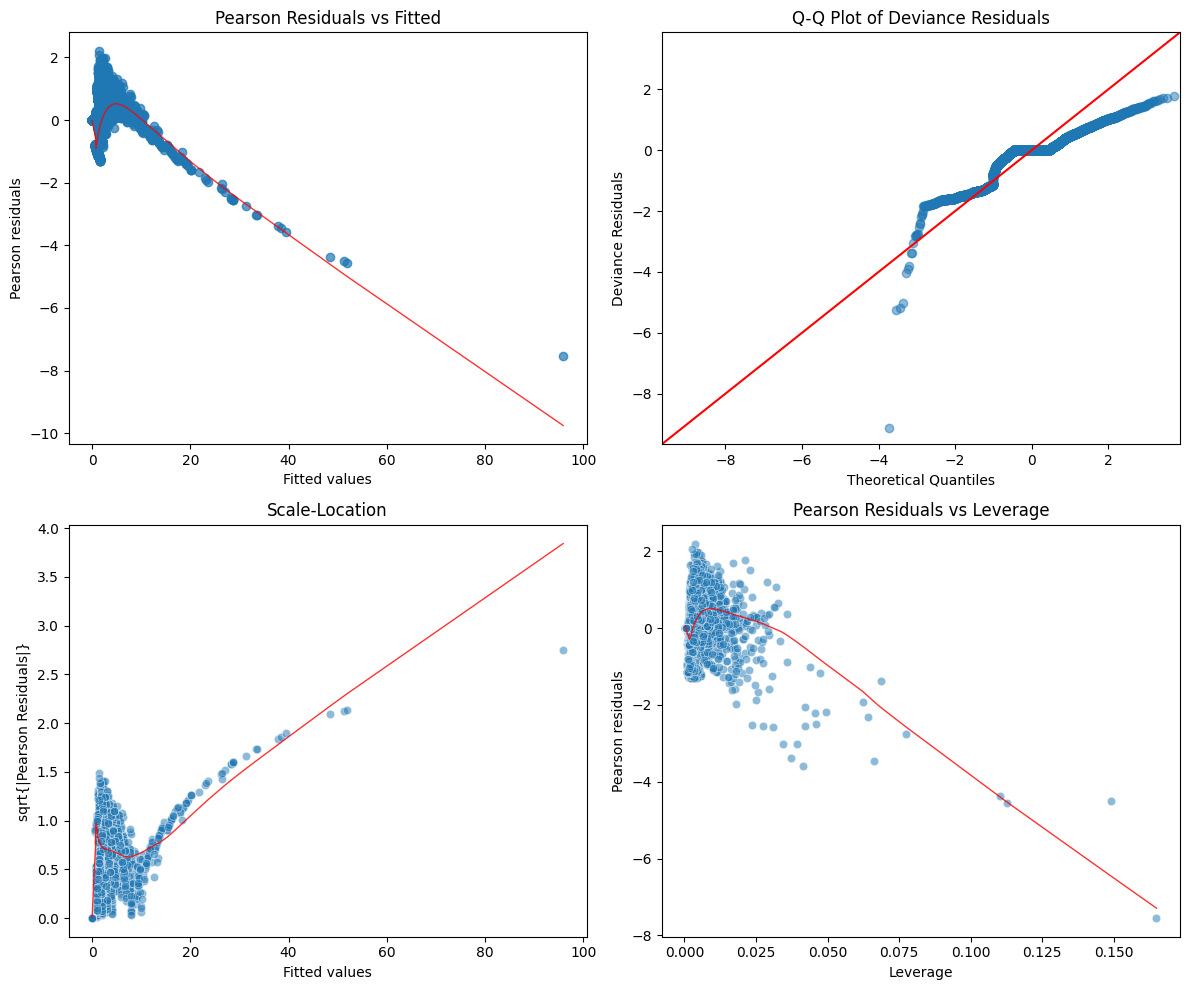

                  Generalized Linear Model Regression Results                  
Dep. Variable:     SPEEDING_VIOLATIONS   No. Observations:                10000
Model:                             GLM   Df Residuals:                     9971
Model Family:                  Poisson   Df Model:                           28
Link Function:                     Log   Scale:                          1.0000
Method:                           IRLS   Log-Likelihood:                -9162.9
Date:                 Sun, 27 Sep 2026   Deviance:                       4578.5
Time:                         01:57:00   Pearson chi2:                 3.25e+03
No. Iterations:                     28   Pseudo R-squ. (CS):             0.9068
Covariance Type:             nonrobust                                         
                                  coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------------------
const   

In [315]:
speeding_pois_model = sm.GLM(
    speeding,
    features_speeding,
    family=sm.families.Poisson()
).fit()
diagnostic_plots_glm(speeding_pois_model)
print(speeding_pois_model.summary())

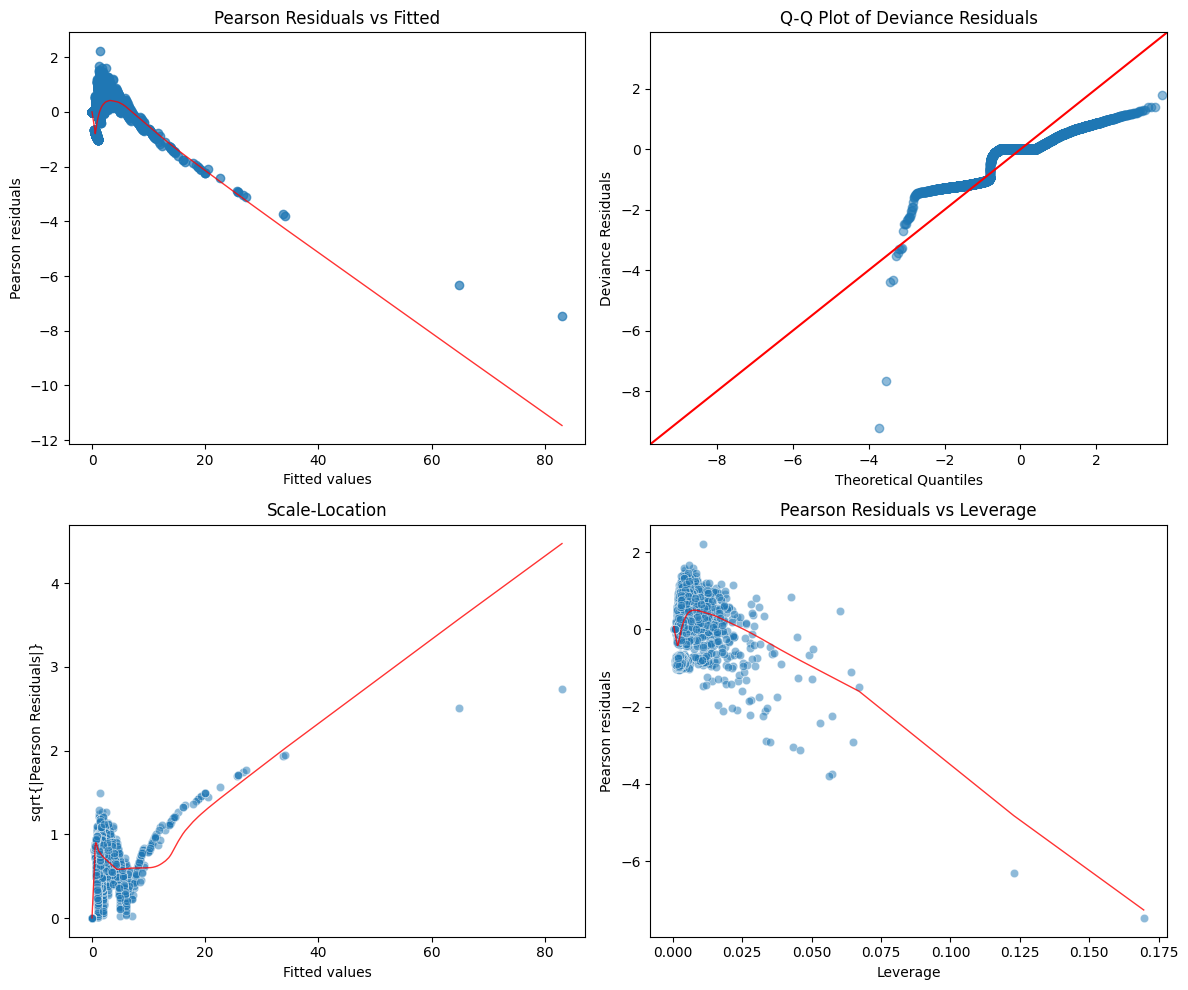

                 Generalized Linear Model Regression Results                  
Dep. Variable:         PAST_ACCIDENTS   No. Observations:                10000
Model:                            GLM   Df Residuals:                     9971
Model Family:                 Poisson   Df Model:                           28
Link Function:                    Log   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -7738.6
Date:                Sun, 27 Sep 2026   Deviance:                       4007.8
Time:                        01:57:16   Pearson chi2:                 2.70e+03
No. Iterations:                    28   Pseudo R-squ. (CS):             0.8327
Covariance Type:            nonrobust                                         
                                  coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------------------
const             

In [316]:
pa_pois_model = sm.GLM(
    past_accidents,
    features_pa,
    family=sm.families.Poisson()
).fit()
diagnostic_plots_glm(pa_pois_model)
print(pa_pois_model.summary())

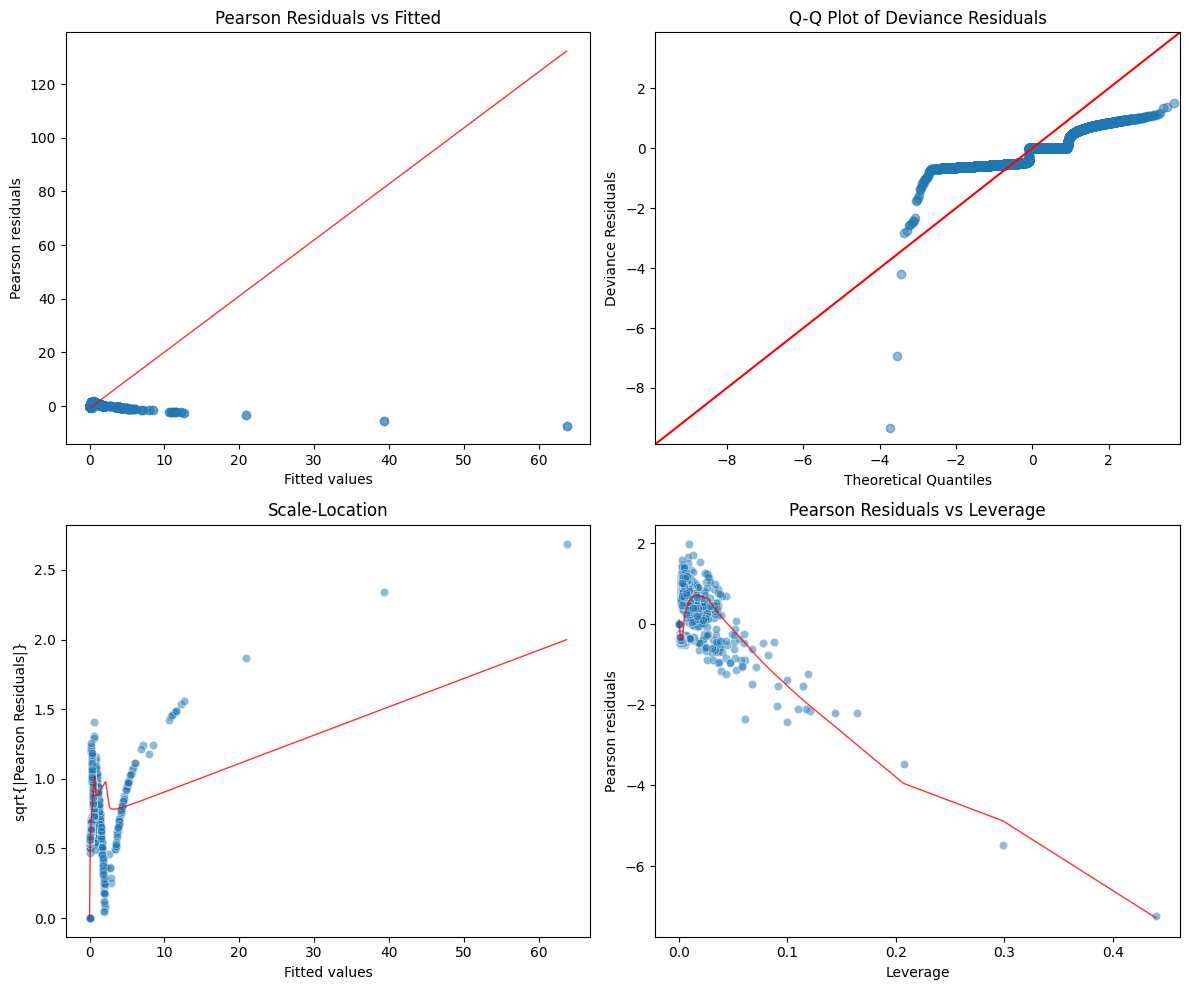

                 Generalized Linear Model Regression Results                  
Dep. Variable:                   DUIS   No. Observations:                10000
Model:                            GLM   Df Residuals:                     9971
Model Family:                 Poisson   Df Model:                           28
Link Function:                    Log   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -3239.4
Date:                Sun, 27 Sep 2026   Deviance:                       2427.0
Time:                        01:57:33   Pearson chi2:                 1.95e+03
No. Iterations:                    26   Pseudo R-squ. (CS):             0.4483
Covariance Type:            nonrobust                                         
                                  coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------------------
const             

In [317]:
duis_pois_model = sm.GLM(
    duis,
    features_duis,
    family=sm.families.Poisson()
).fit()
diagnostic_plots_glm(duis_pois_model)
print(duis_pois_model.summary())

## Task 7: Zero Inflated Poisson Regression on count based features: Past Accidents, DUIs, and Speeding Violations

### Diagnostic plot code for ZIP

In [318]:
def diagnostic_zip(model, y):
  fitted = model.predict(which="mean")
  residuals = y - fitted
  pearson_resid = residuals / np.sqrt(
      np.maximum(fitted, 1e-8)
  )
  scale_resid = np.sqrt(np.abs(pearson_resid))
  fig, axes = plt.subplots(2, 2, figsize=(12, 10))

  ax = axes[0, 0]
  sns.scatterplot(
      x=fitted,
      y=pearson_resid,
      alpha=0.5,
      ax=ax
  )
  sns.regplot(
      x=fitted,
      y=pearson_resid,
      scatter=False,
      lowess=True,
      ci=None,
      line_kws={'color': 'red', 'lw': 1, 'alpha': 0.8},
      ax=ax
  )

  ax.set_title("Pearson Residuals vs Fitted")
  ax.set_xlabel("Predicted mean")
  ax.set_ylabel("Pearson residuals")

  ax = axes[0, 1]

  QQ = ProbPlot(pearson_resid)
  QQ.qqplot(
      line="45",
      alpha=0.5,
      ax=ax
  )
  ax.set_title("Q-Q Plot of Pearson Residuals")
  ax.set_xlabel("Theoretical Quantiles")
  ax.set_ylabel("Pearson Residuals")

  ax = axes[1, 0]
  sns.scatterplot(
      x=fitted,
      y=scale_resid,
      alpha=0.5,
      ax=ax
  )

  sns.regplot(
      x=fitted,
      y=scale_resid,
      scatter=False,
      lowess=True,
      ci=None,
      line_kws={'color': 'red', 'lw': 1, 'alpha': 0.8},
      ax=ax
  )

  ax.set_title("Scale-Location")
  ax.set_xlabel("Predicted mean")
  ax.set_ylabel("sqrt{|Pearson Residuals|}")

  ax = axes[1, 1]
  sns.scatterplot(
      x=fitted,
      y=y,
      alpha=0.5,
      ax=ax
  )

  min_value = min(fitted.min(), y.min())
  max_value = max(fitted.max(), y.max())
  ax.plot(
      [min_value, max_value],
      [min_value, max_value],
      color="black",
      linestyle="--",
      linewidth=1
  )

  ax.set_title("Observed vs Predicted")
  ax.set_xlabel("Predicted mean")
  ax.set_ylabel("Observed count")
  plt.tight_layout()
  plt.show()

### Models

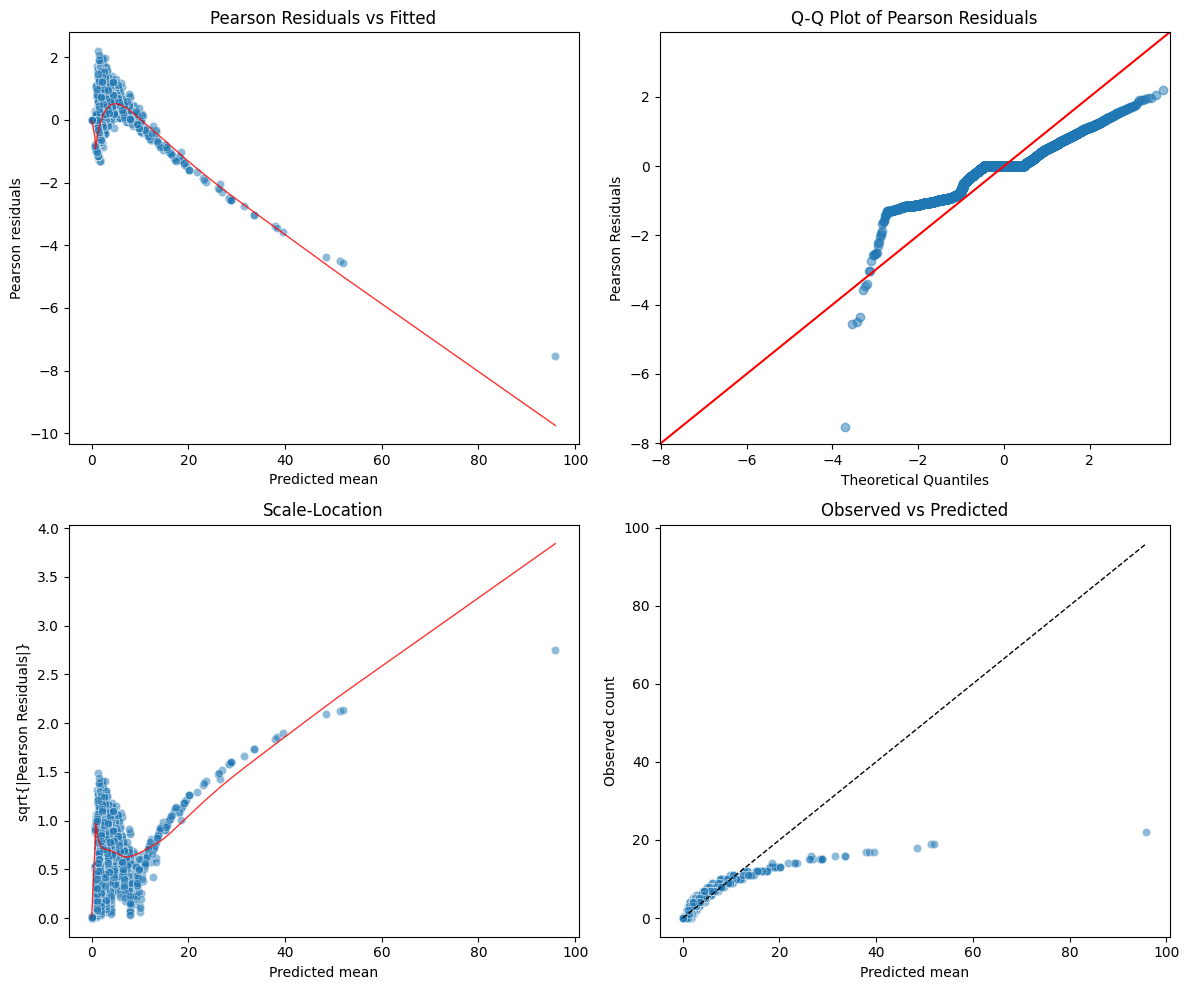

                     ZeroInflatedPoisson Regression Results                    
Dep. Variable:     SPEEDING_VIOLATIONS   No. Observations:                10000
Model:             ZeroInflatedPoisson   Df Residuals:                     9971
Method:                            MLE   Df Model:                           28
Date:                 Sun, 27 Sep 2026   Pseudo R-squ.:                  0.4708
Time:                         01:57:46   Log-Likelihood:                -9162.9
converged:                        True   LL-Null:                       -17316.
Covariance Type:             nonrobust   LLR p-value:                     0.000
                                  coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------------------
inflate_const                 -17.9688    160.960     -0.112      0.911    -333.445     297.507
const                          -0.2531      0.082     -3.079      0.002 

In [319]:
speeding_zip_model = ZeroInflatedPoisson(
    speeding,
    features_speeding,
    inflation="logit"
).fit(method="bfgs", maxiter=1000, disp=False)
diagnostic_zip(speeding_zip_model, speeding)
print(speeding_zip_model.summary())

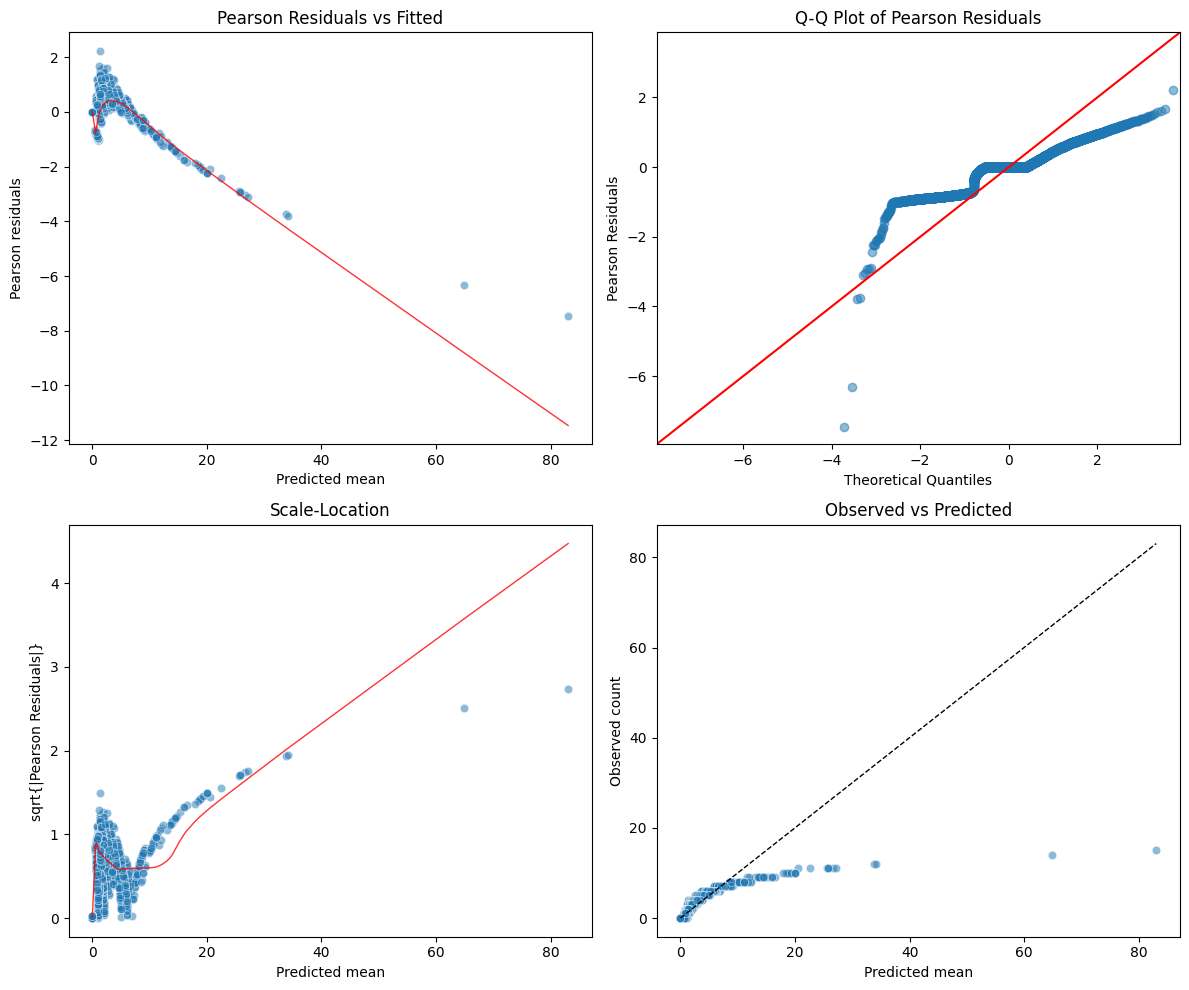

                     ZeroInflatedPoisson Regression Results                    
Dep. Variable:          PAST_ACCIDENTS   No. Observations:                10000
Model:             ZeroInflatedPoisson   Df Residuals:                     9971
Method:                            MLE   Df Model:                           28
Date:                 Sun, 27 Sep 2026   Pseudo R-squ.:                  0.4632
Time:                         01:57:58   Log-Likelihood:                -7738.6
converged:                        True   LL-Null:                       -14416.
Covariance Type:             nonrobust   LLR p-value:                     0.000
                                  coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------------------
inflate_const                 -16.1286     64.441     -0.250      0.802    -142.430     110.173
const                          -0.6184      0.100     -6.200      0.000 

In [320]:
pa_zip_model = ZeroInflatedPoisson(
    past_accidents,
    features_pa,
    inflation="logit"
).fit(method="bfgs", maxiter=1000, disp=False)
diagnostic_zip(pa_zip_model, past_accidents)
print(pa_zip_model.summary())

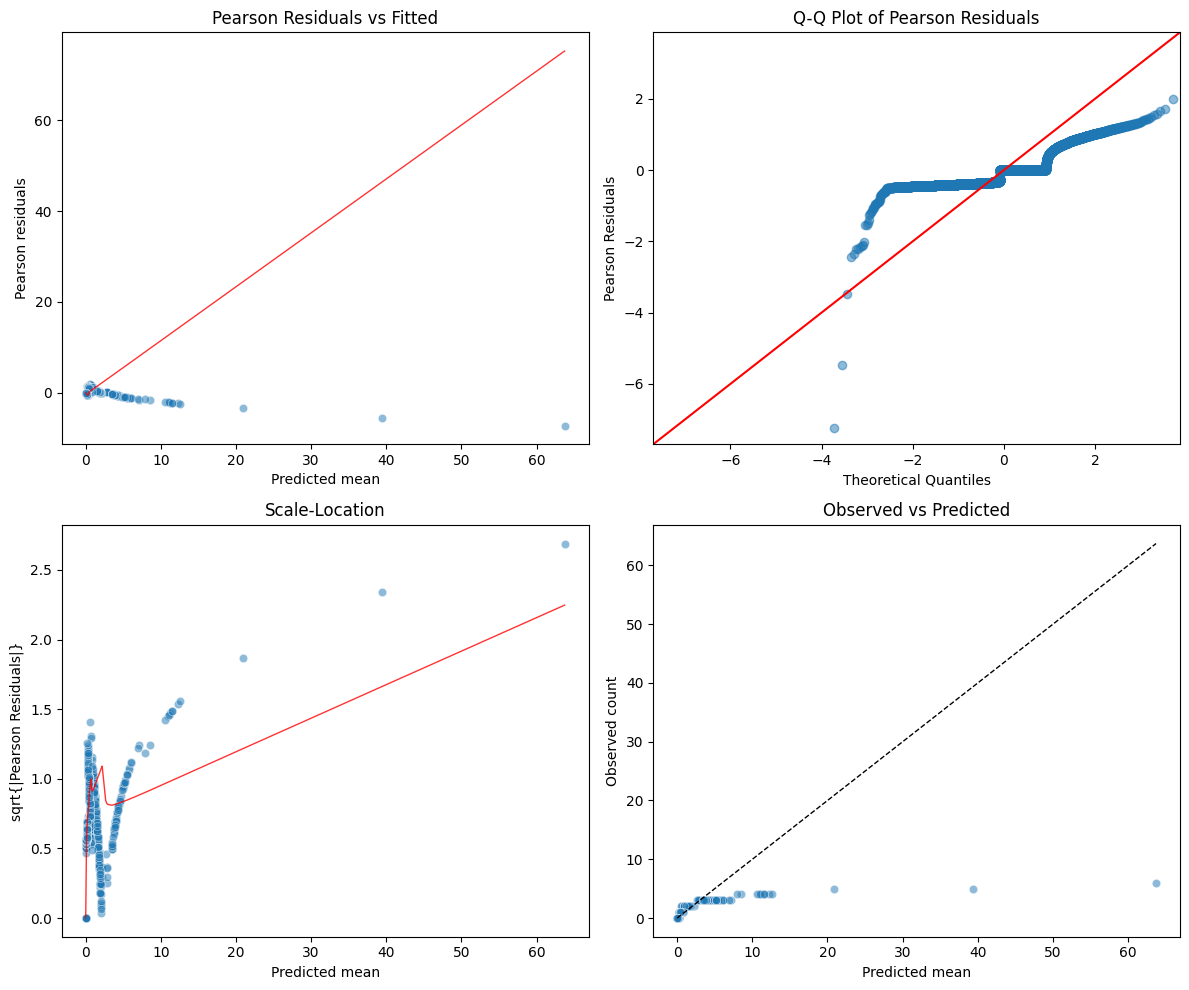

                     ZeroInflatedPoisson Regression Results                    
Dep. Variable:                    DUIS   No. Observations:                10000
Model:             ZeroInflatedPoisson   Df Residuals:                     9971
Method:                            MLE   Df Model:                           28
Date:                 Sun, 27 Sep 2026   Pseudo R-squ.:                  0.4671
Time:                         01:58:11   Log-Likelihood:                -3239.4
converged:                        True   LL-Null:                       -6078.8
Covariance Type:             nonrobust   LLR p-value:                     0.000
                                  coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------------------
inflate_const                 -46.4963   1.99e+06  -2.33e-05      1.000   -3.91e+06    3.91e+06
const                          -2.0378      0.207     -9.841      0.000 

In [321]:
duis_zip_model = ZeroInflatedPoisson(
    duis,
    features_duis,
    inflation="logit"
).fit(method="bfgs", maxiter=1000, disp=False)
diagnostic_zip(duis_zip_model, duis)
print(duis_zip_model.summary())

## Task 8: Cluster Analysis

Using: ['CREDIT_SCORE', 'ANNUAL_MILEAGE', 'SPEEDING_VIOLATIONS', 'DUIS', 'PAST_ACCIDENTS', 'VEHICLE_OWNERSHIP', 'MARRIED', 'CHILDREN']


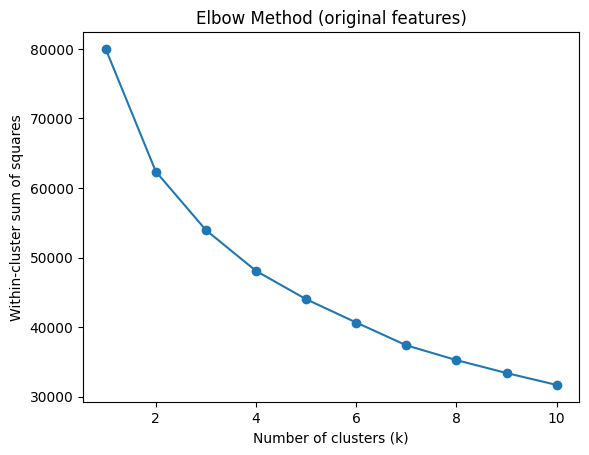

Elbow point k = 4
         CREDIT_SCORE  ANNUAL_MILEAGE  SPEEDING_VIOLATIONS  DUIS  \
CLUSTER                                                            
0                0.57            0.40                 0.22  0.16   
1                0.44            0.60                 0.02  0.02   
2                0.48            0.51                 0.04  0.02   
3                0.56            0.42                 0.05  0.02   

         PAST_ACCIDENTS  VEHICLE_OWNERSHIP  MARRIED  CHILDREN  CLAIM_RATE  
CLUSTER                                                                    
0                  0.22               0.84     0.77       0.9        0.06  
1                  0.03               0.56     0.17       0.0        0.53  
2                  0.04               0.63     0.01       1.0        0.38  
3                  0.05               0.79     1.00       0.9        0.21  
CLUSTER
3    3275
1    2637
2    2473
0    1615
Name: count, dtype: int64


In [322]:
columns = ["CREDIT_SCORE", "ANNUAL_MILEAGE", "SPEEDING_VIOLATIONS", "DUIS",
           "PAST_ACCIDENTS", "VEHICLE_OWNERSHIP", "MARRIED", "CHILDREN"]

available = []
for c in columns:
    if c in encoded_data.columns:
        available.append(c)

columns = available
print("Using:", columns)

cluster_data = encoded_data[columns].astype(float)

scaler = StandardScaler()
cluster_scaled = scaler.fit_transform(cluster_data)

# elbow method on the original features
within_cluster_sum_of_squares = []
for k in range(1, 11):
    kmeans_test = KMeans(n_clusters=k, n_init=10, random_state=44)
    kmeans_test.fit(cluster_scaled)
    within_cluster_sum_of_squares.append(kmeans_test.inertia_)

plt.plot(range(1, 11), within_cluster_sum_of_squares, marker="o")
plt.xlabel("Number of clusters (k)")
plt.ylabel("Within-cluster sum of squares")
plt.title("Elbow Method (original features)")
plt.show()

# find the elbow point
k_list = np.array(range(1, 11))
scores = np.array(within_cluster_sum_of_squares)
k_scaled = (k_list - k_list.min()) / (k_list.max() - k_list.min())
scores_scaled = (scores - scores.min()) / (scores.max() - scores.min())
distance = np.abs(scores_scaled - (1 - k_scaled))
best_k_original = k_list[np.argmax(distance)]
print("Elbow point k =", best_k_original)

# final model
km = KMeans(n_clusters=best_k_original, n_init=10, random_state=44)
km.fit(cluster_scaled)

cluster_data["CLUSTER"] = km.labels_
cluster_data["CLAIM_RATE"] = outcome.values

cluster_summary_original = cluster_data.groupby("CLUSTER").mean()
cluster_summary_original = cluster_summary_original.round(2)
print(cluster_summary_original)

print(cluster_data["CLUSTER"].value_counts())

Using: ['CREDIT_SCORE', 'VEHICLE_OWNERSHIP', 'INSURANCE_RISK', 'FAMILY']


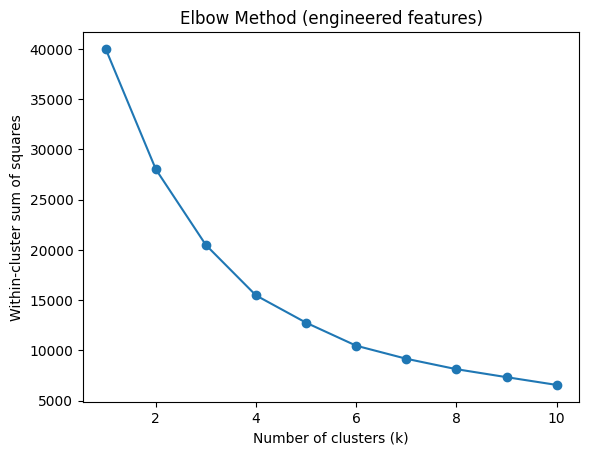

         CREDIT_SCORE  VEHICLE_OWNERSHIP  INSURANCE_RISK  FAMILY  CLAIM_RATE
CLUSTER                                                                     
0                0.54               1.00            0.06    1.00        0.20
1                0.45               0.00            0.07    1.00        0.52
2                0.44               0.56            0.03    0.00        0.55
3                0.60               0.92            0.32    0.98        0.05
CLUSTER
0    4188
2    2196
1    1938
3    1678
Name: count, dtype: int64
k original = 4  k engineered = 4
Agreement between the two clusterings (ARI): 0.401


In [323]:
from sklearn.metrics import adjusted_rand_score

columns = ["CREDIT_SCORE", "VEHICLE_OWNERSHIP", "INSURANCE_RISK", "FAMILY",
           "CAR_AGE_Old", "CAR_AGE_Very Old"]

available = []
for c in columns:
    if c in data.columns:
        available.append(c)

columns = available
print("Using:", columns)

engineered_data = data[columns].astype(float)

scaler = StandardScaler()
engineered_scaled = scaler.fit_transform(engineered_data)

# elbow method on engineered features
within_cluster_sum_of_squares = []
for k in range(1, 11):
    kmeans_test = KMeans(n_clusters=k, n_init=10, random_state=44)
    kmeans_test.fit(engineered_scaled)
    within_cluster_sum_of_squares.append(kmeans_test.inertia_)

plt.plot(range(1, 11), within_cluster_sum_of_squares, marker="o")
plt.xlabel("Number of clusters (k)")
plt.ylabel("Within-cluster sum of squares")
plt.title("Elbow Method (engineered features)")
plt.show()

#taking elbow point as same as original feature to compare the result i.e k=4

# final model
kmeans_engineered = KMeans(n_clusters=4, n_init=10, random_state=44)
kmeans_engineered.fit(engineered_scaled)

engineered_data["CLUSTER"] = kmeans_engineered.labels_
engineered_data["CLAIM_RATE"] = outcome.values

cluster_summary_engineered = engineered_data.groupby("CLUSTER").mean()
cluster_summary_engineered = cluster_summary_engineered.round(2)
print(cluster_summary_engineered)

print(engineered_data["CLUSTER"].value_counts())

# compare the two clusterings
ari_score = adjusted_rand_score(km.labels_, kmeans_engineered.labels_)
print("k original =", best_k_original, " k engineered =", 4)
print("Agreement between the two clusterings (ARI):", round(ari_score, 3))

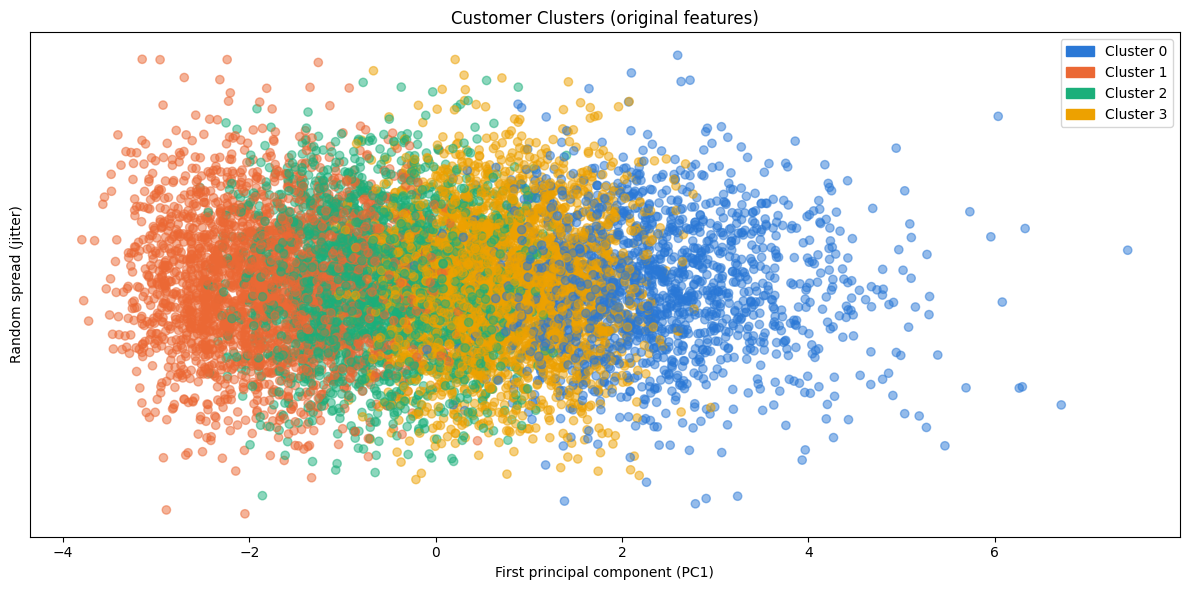

In [324]:
from sklearn.decomposition import PCA
from matplotlib.patches import Patch

color_map = {0: "#2a78d6", 1: "#eb6834", 2: "#1baf7a", 3: "#eda100"}

cluster_plot = pd.DataFrame()
cluster_plot["x_point"] = PCA(n_components=1, random_state=44).fit_transform(cluster_scaled)[:, 0]
cluster_plot["y_spread"] = np.random.default_rng(44).normal(0, 1, len(cluster_plot))
cluster_plot["cluster"] = km.labels_
cluster_plot["color"] = cluster_plot["cluster"].map(color_map)

plt.figure(figsize=(12, 6))
plt.scatter(cluster_plot["x_point"], cluster_plot["y_spread"], c=cluster_plot["color"], alpha=0.5)
plt.legend(handles=[Patch(color=color_map[c], label=f"Cluster {c}") for c in sorted(color_map)])
plt.title("Customer Clusters (original features)")
plt.xlabel("First principal component (PC1)")
plt.ylabel("Random spread (jitter)")
plt.yticks([])
plt.tight_layout()
plt.show()

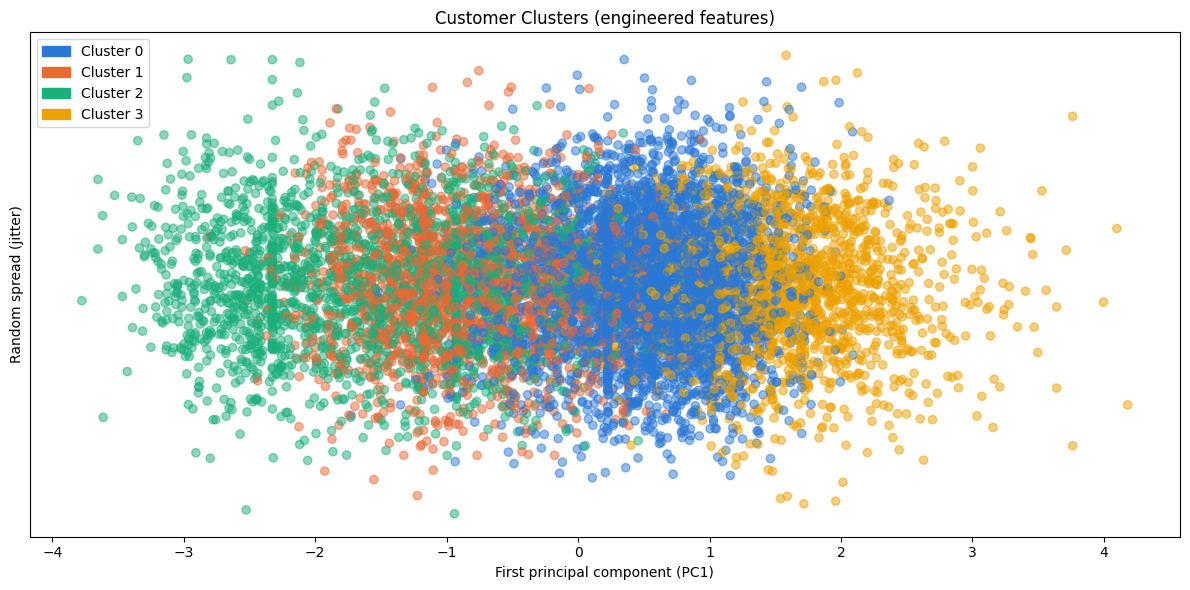

In [325]:
# ---------------------------------------------------------------
# Visualization of clusters (engineered features)
# ---------------------------------------------------------------
engineered_plot = pd.DataFrame()

engineered_plot["x_point"] = PCA(n_components=1, random_state=44).fit_transform(engineered_scaled)[:, 0]
engineered_plot["y_spread"] = np.random.default_rng(44).normal(0, 1, len(engineered_plot))
engineered_plot["cluster"] = kmeans_engineered.labels_
engineered_plot["color"] = engineered_plot["cluster"].map(color_map)

plt.figure(figsize=(12, 6))
plt.scatter(engineered_plot["x_point"], engineered_plot["y_spread"], c=engineered_plot["color"], alpha=0.5)
plt.legend(handles=[Patch(color=color_map[c], label=f"Cluster {c}") for c in sorted(color_map)])
plt.title("Customer Clusters (engineered features)")
plt.xlabel("First principal component (PC1)")
plt.ylabel("Random spread (jitter)")
plt.yticks([])
plt.tight_layout()
plt.show()

## Task 9: Chi-Square Test

In [326]:
# --- Chi-square test of independence against the target ---------------
from scipy.stats import chi2_contingency

def chi_square_test(df, feature, target):
    """
    Chi-square test of independence between one categorical column and the target.

    H0: the feature and the target are independent.
    """

    table = pd.crosstab(df[feature], df[target])

    chi2, p_value, dof, expected = chi2_contingency(table)

    return {
        "feature": feature,
        "chi2": round(chi2, 1),
        "dof": dof,
        "p_value": p_value,
        "n_categories": table.shape[0],
        "min_expected": round(expected.min(), 1),
        "significant": p_value < 0.05,
    }


def chi_square_summary(df, columns, target):
    # Run the chi-square test for every categorical column and rank the results.
    results = pd.DataFrame([chi_square_test(df, col, target) for col in columns])
    return results.sort_values("chi2", ascending=False).reset_index(drop=True)


chi2_results = chi_square_summary(brian_data, groups["categorical"], "OUTCOME")
display(chi2_results)

print(f"significant at 0.05: {chi2_results['significant'].sum()} "
      f"of {len(chi2_results)}")
print("NOT associated with OUTCOME:",
      chi2_results.loc[~chi2_results["significant"], "feature"].tolist())
print("smallest expected count anywhere:",
      chi2_results["min_expected"].min(), "(needs to be >= 5)")

,feature,chi2,dof,p_value,n_categories,min_expected,significant
0,DRIVING_EXPERIENCE,2806.5,2,0.000000e+00,3,993.5,True
1,AGE,2308.8,3,0.000000e+00,4,623.5,True
2,INCOME,1798.0,3,0.000000e+00,4,536.4,True
3,CAR_AGE,1063.4,2,1.198556e-231,3,628.5,True
4,VEHICLE_YEAR,864.0,1,6.485680e-190,2,950.2,True
5,POSTAL_CODE,388.1,3,8.295931e-84,4,37.6,True
6,EDUCATION,365.4,2,4.577462e-80,3,600.0,True
7,GENDER,114.5,1,1.026508e-26,2,1563.4,True
8,RACE,0.6,1,4.284492e-01,2,309.5,False
9,VEHICLE_TYPE,0.3,1,6.090480e-01,2,149.4,False


significant at 0.05: 8 of 10
NOT associated with OUTCOME: ['RACE', 'VEHICLE_TYPE']
smallest expected count anywhere: 37.6 (needs to be >= 5)


## Task 10: Correlation Matrix

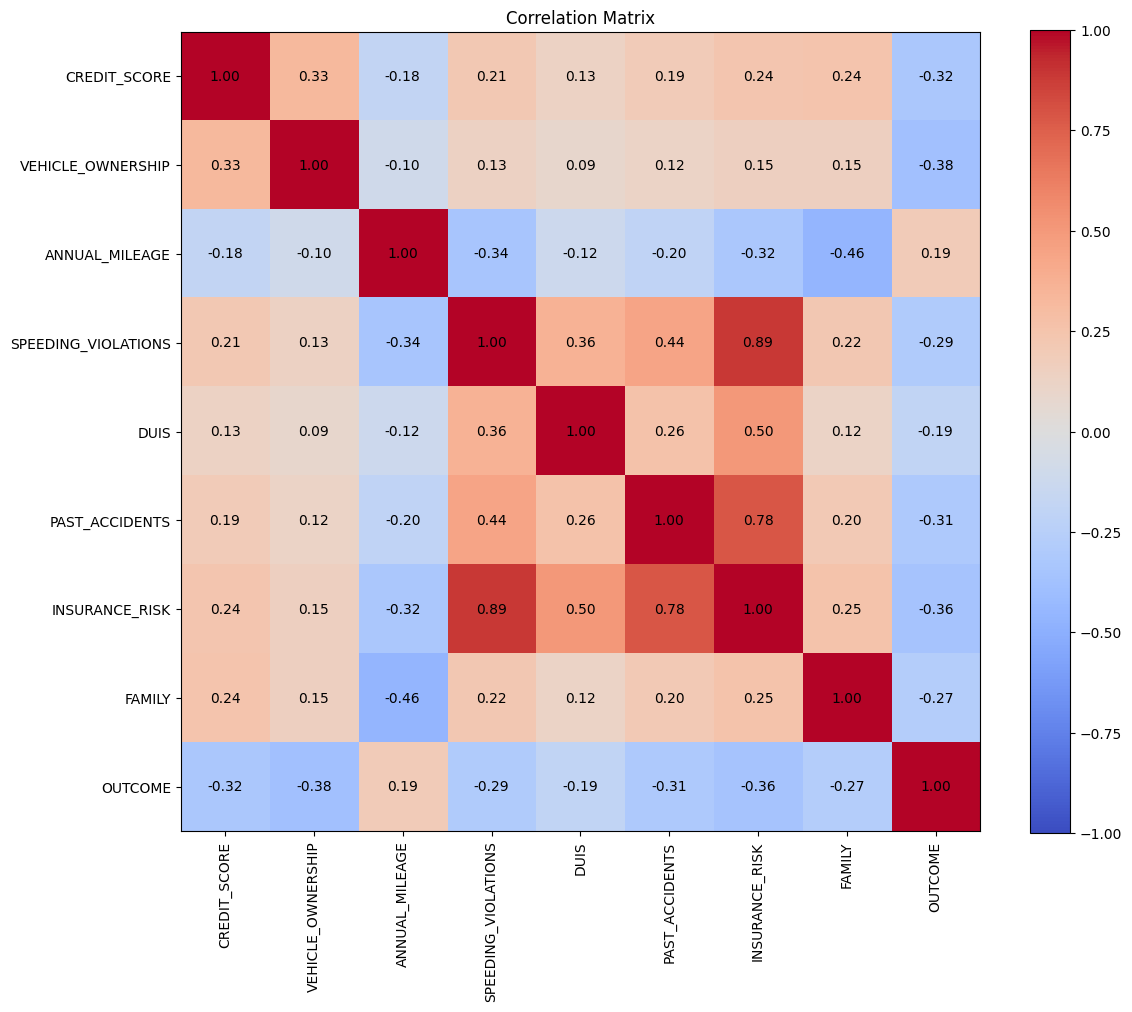

In [327]:
# Plot a correlation matrix for all numeric columns in a dataset.
def plot_correlation_matrix(dataset):
    numeric_data = dataset.select_dtypes(include="number")

    corr_matrix = numeric_data.corr()

    fig, ax = plt.subplots(figsize=(12, 10))
    heatmap = ax.imshow(corr_matrix, cmap="coolwarm", vmin=-1, vmax=1)

    ax.set_xticks(range(len(corr_matrix.columns)))
    ax.set_yticks(range(len(corr_matrix.columns)))
    ax.set_xticklabels(corr_matrix.columns, rotation=90)
    ax.set_yticklabels(corr_matrix.columns)

    for i in range(len(corr_matrix.columns)):
        for j in range(len(corr_matrix.columns)):
            ax.text(
                j, i,
                f"{corr_matrix.iloc[i, j]:.2f}",
                ha="center",
                va="center"
            )

    fig.colorbar(heatmap)

    ax.set_title("Correlation Matrix")
    plt.tight_layout()
    plt.show()

plot_correlation_matrix(brian_data)

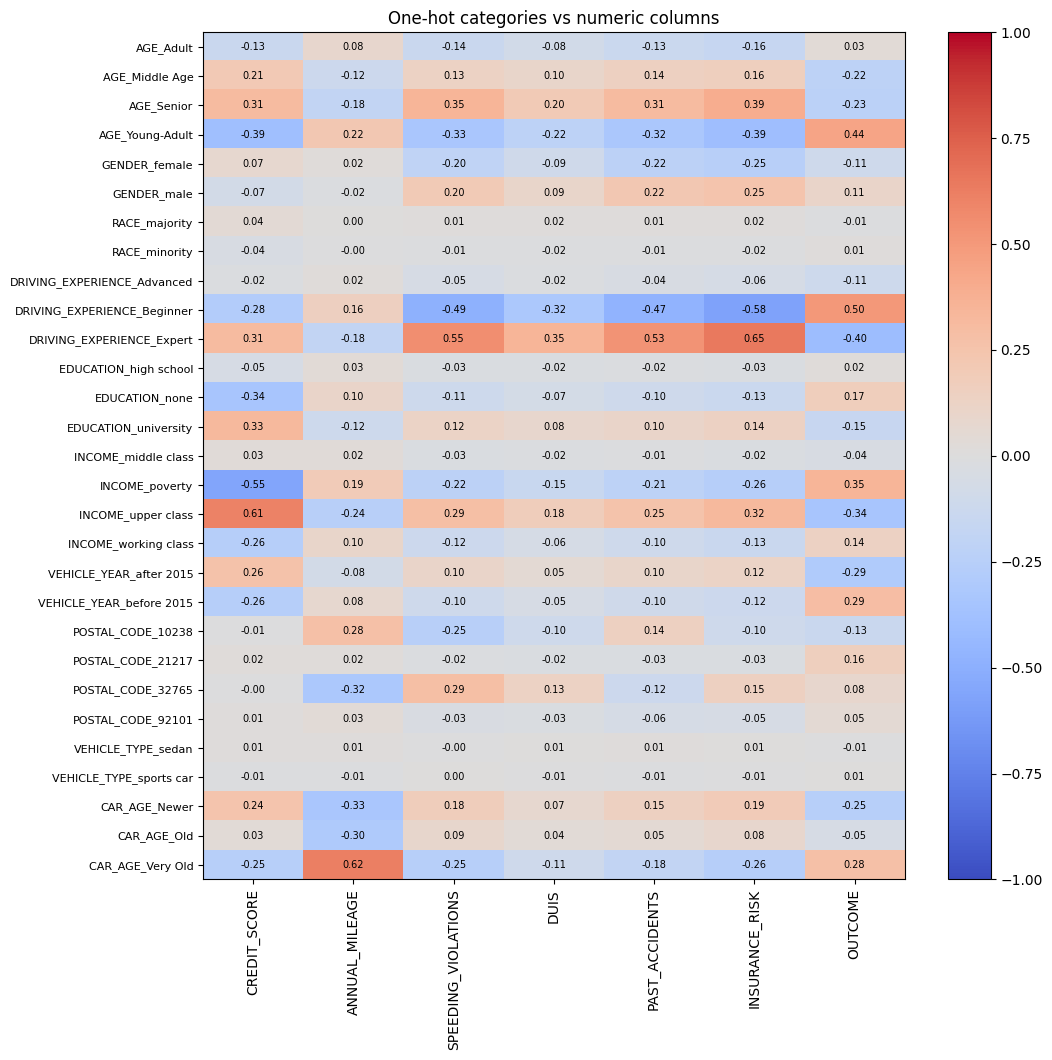

In [328]:
# --- Correlation for the categorical columns ---------------------------
def plot_onehot_numeric_correlation(df, categorical_cols, numeric_cols):
    dummies = pd.get_dummies(df[categorical_cols].astype(str), dtype=int)

    grid = pd.DataFrame({col: dummies.corrwith(df[col]) for col in numeric_cols})

    fig, ax = plt.subplots(figsize=(1. * len(numeric_cols) + 4,
                                    0.3 * len(grid) + 2))

    heatmap = ax.imshow(grid, cmap="coolwarm", vmin=-1, vmax=1, aspect="auto")

    ax.set_xticks(range(len(grid.columns)))
    ax.set_yticks(range(len(grid.index)))
    ax.set_xticklabels(grid.columns, rotation=90)
    ax.set_yticklabels(grid.index, fontsize=8)

    for i in range(len(grid.index)):
        for j in range(len(grid.columns)):
            ax.text(j, i, f"{grid.iloc[i, j]:.2f}",
                    ha="center", va="center", fontsize=7)

    fig.colorbar(heatmap)
    ax.set_title("One-hot categories vs numeric columns")
    plt.tight_layout()
    plt.show()

    return grid


numeric_targets = groups["continuous"] + groups["count"] + ["OUTCOME"]
onehot_grid = plot_onehot_numeric_correlation(
    brian_data, groups["categorical"], numeric_targets
)

## Task 11: Flip Ratio

In [329]:
fair_features = encoded_data
fair_train, fair_test, claim_train, claim_test = train_test_split(
    fair_features, outcome, test_size=0.2, random_state=123, stratify=outcome
)

claim_classifier = LogisticRegression(max_iter=1000).fit(fair_train, claim_train)
original_pred = claim_classifier.predict(fair_test)

In [330]:
sensitive_features = ["GENDER_male", "RACE_minority", "MARRIED", "CHILDREN"]
flip_rows = []
for feature in sensitive_features:
    flipped_test = fair_test.copy()
    flipped_test[feature] = 1 - flipped_test[feature]
    flipped_pred = claim_classifier.predict(flipped_test)
    flip_rows.append({"feature": feature,
                      "flip_ratio": (flipped_pred!=original_pred).mean(),
                      "No Claim-> Claim": ((original_pred==0)&(flipped_pred==1)).sum(),
                      "Claim -> No Claim": ((original_pred==1) & (flipped_pred==0)).sum()})

flip_ratio_table = pd.DataFrame(flip_rows).sort_values("flip_ratio", ascending=False)
print(flip_ratio_table)

         feature  flip_ratio  No Claim-> Claim  Claim -> No Claim
0    GENDER_male      0.1340               136                132
2        MARRIED      0.0435                44                 43
3       CHILDREN      0.0175                24                 11
1  RACE_minority      0.0120                 4                 20
